# Does meta-labeling add economic value over inverse-volatility sizing when the four strategies share one capital?

**Question.** In `meta_labeling_economic_value_quant_forge.ipynb` (the *source*), on the 20 `NEW` assets that the meta-models
never trained on, the AFML probability sizing on top of inverse volatility (`D×P`) beat inverse volatility alone (`D`) by
**+0.228 Sharpe** [+0.01, +0.47] when every trade was evaluated without a capital limit, and by only **+0.072** in a
capital-constrained replay. That replay had two shortcuts: the budget was the 95th percentile of the uniform rule's exposure
**measured on the evaluated trades themselves** (chosen after the fact), and each trade's whole PnL was booked in its **exit
month**. This notebook asks how much of the advantage survives when the four strategies trade **one shared portfolio**,
chronologically, with a **budget fixed in advance**, positions **marked to market at every 4-hour bar**, and Sharpe computed from
**daily returns of the portfolio value**.

**What is held fixed.** Same 40 assets and `SEEN` / `NEW` split, same four primary strategies with their default rules, same
trades, the same out-of-sample meta-model predictions (28 walk-forward windows, read from the source's cache: no refitting, no
tuning, no new strategy), the same sizing rules and their training-side constants, the same 5 bps per fill and the same 10-unit
position cap. Main comparison: **`D×P` vs `D` on `NEW`**; `U` (fixed size) and `P` (meta-model only) are references; `SEEN` is
reported separately.

**Three questions.** (1) How much does the meta-model add at portfolio level — return, Sharpe from daily returns, drawdown,
exposure, turnover, a paired day-block bootstrap of `D×P − D`, and the cost level at which the advantage disappears? (2) Where does
the difference come from — by strategy and year, using the positions actually allocated in the shared portfolio, and how much
depends on SuperTrend, on a single year, or on exposure differences? (3) What do the results support: continuing with the
meta-model on the whole portfolio, a focused experiment on one strategy, or `D`?

### What is reused, and from where

| Component | Reused from |
|---|---|
| 4h Binance bars, `SEEN`/`NEW` universes, trade panel of the four strategies (5 bps, next-bar-open execution) | `quant_forge.data.load_binance_bars`, `quant_forge.metalabeling.build_trade_panel` — exactly as in the source §2 and §5 |
| Out-of-sample meta-model probabilities and every training-side constant (28 fitted windows) | the source's walk-forward cache `~/.cache/quantforge/meta_econ_qf/<hash>` (same cache key: configuration, windows, FFD order, data fingerprint, library version), read with `quant_forge.utils.DiskCache` |
| Sizing rules `U`, `D`, `P`, `D×P`, normalisation to equal expected exposure per signal, 10-unit cap | `quant_forge.sizing.normalized_sizes` (source §9.1) |
| Reproduction of the source numbers (monthly exit-month economics, capital replay) | `quant_forge.evaluation.evaluate_sizing`, `quant_forge.sizing.capital_constrained_sizes` (source §9.2, §9.5) |
| Daily mark-to-market cross-check, paired **monthly block bootstrap** of daily series, paired differences | `quant_forge.evaluation.portfolio` (`daily_close_panel`, `expand_trade_days`, `daily_pnl`, `bootstrap_sharpe`, `paired_differences`, `month_labels`), the method of `research/bar_types/bar_type_frequency_meta_labeling.ipynb` §6 |
| Permutation of sizes within strategy × window as the "no information" null | the permutation test of `quant_forge.evaluation.evaluate_sizing` (source §9.2), here re-run through the portfolio simulation |
| Budget statistic (95th percentile of `U`'s open exposure) | source §9.2, here measured ex ante on `SEEN` before the evaluation |
| **New in this notebook** | the shared-capital 4h portfolio simulator (pro-rata allocation of simultaneous signals, gross limit on marked-to-market exposure, compounding), the ex-ante budget, the cost/budget sweeps and the decompositions of §6 |

### What has already been seen (evidence quality)

The `NEW` assets were used once by `meta_labeling_sizing_vs_prior` (frozen run plus a post-hoc section) and again by the source,
whose `D×P − D` result **is the reason this notebook exists**: the comparison was chosen *because* it looked good on `NEW`. The
model fitting stays clean (no model ever trained on a `NEW` asset), but the choice of hypothesis does not, so every interval below is
optimistic and a positive result here can only justify a test on data not yet seen. `SEEN` is the development universe (periods A
and B used many times) and is not cleaner evidence. Period C (decided after 2026-09-01) is ~2.5 months long.

## 1. Configuration

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
import sys, time, warnings, importlib.metadata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display
from numba import njit


def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "quant_forge/strategies").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")


ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import quant_forge
import quant_forge.strategies as qs
from quant_forge import data as qd, features as qf, metalabeling as ml, evaluation as qe, sizing as qz
from quant_forge.validation import calendar_windows
from quant_forge.utils import DEFAULT_CACHE_ROOT, DiskCache, frame_fingerprint

SEEN, NEW = qd.SEEN_ASSETS, qd.NEW_ASSETS
ALL_ASSETS = SEEN + NEW
GROUPS = ["NEW", "SEEN"]                       # NEW first: the transfer result is the main one
DATA_END = pd.Timestamp("2026-11-19 00:00", tz="UTC")
EVAL_START = pd.Timestamp("2019-03-01", tz="UTC")
WARMUP_DAYS, BPD = 30, 6
FEE_BPS, NOTIONAL, SIZE_CAP = 5.0, 10_000.0, 10.0

# exactly the source's walk-forward configuration (needed to address its cache)
WINDOWS = calendar_windows("2019-03-01", end=DATA_END, years=1)
FFD_GRID, FFD_THRESH = [round(0.1 * i, 1) for i in range(0, 11)], 1e-4
CONFIG = ml.MetaLabelingConfig(train_assets=tuple(SEEN), seed=0, cover_all_events=False)
S = qs.Strategies
STRATEGIES = {S.RSI_CROSS_ABOVE: "RSI", S.DONCHIAN_BREAKOUT_CONTINUATION: "DONCHIAN",
              S.TIS_BTC_MOMENTUM_CONFLUENCE: "TIS", S.SUPERTREND_REGIME_CONFLUENCE: "SUPERTREND"}
SS = list(STRATEGIES.values())

# the four portfolio variants (quant_forge.sizing rule names)
RULES = ["U", "D", "P", "DxP"]
RULE_NAME = {"U": "U fixed size", "D": "D inverse volatility", "P": "P meta-model only", "DxP": "D×P inverse vol. × meta-model"}

# portfolio
GROSS_LIMIT = 1.0                              # gross market value of open positions <= 100 % of portfolio value
GRID = pd.date_range(EVAL_START, DATA_END, freq="4h")          # 4h bar ends at which positions are marked
CAL = pd.date_range(EVAL_START, DATA_END - pd.Timedelta(days=1), freq="D")   # 2 820 UTC days of daily returns
MONTHS = qe.month_labels(CAL)
DAYS_PER_YEAR = 365.0

# uncertainty and sweeps
N_BOOT, N_PERM, SEED = 2000, 1000, 0
BLOCK_DAYS = [10, "month", 63, 126]            # block lengths for the day-block bootstrap (calendar month = main)
BUDGETS = [20, 25, 30, 35, 40, 50, 60, 80]     # sensitivity of the result to the budget (units)
SLIPPAGE_BPS = [0, 2, 5, 10, 15, 20, 30, 40, 50]   # added to the 5 bps fee, per fill
BORROW_ANN = [0.0, 0.10, 0.20]                 # annual cost of borrowing for short positions (SuperTrend)

# values printed by the source notebook (meta_labeling_economic_value_quant_forge.ipynb, cells 39 and 46)
SOURCE = {("NEW", "no budget"): {"U": 0.701, "D": 0.881, "P": 0.907, "DxP": 1.109, "DxP − D": (0.228, 0.014, 0.474)},
          ("SEEN", "no budget"): {"U": 1.069, "D": 1.238, "P": 1.201, "DxP": 1.409, "DxP − D": (0.171, -0.013, 0.369)},
          ("NEW", "capital replay"): {"U": 0.641, "D": 0.740, "P": 0.776, "DxP": 0.812},
          ("SEEN", "capital replay"): {"U": 1.010, "D": 1.143, "P": 1.065, "DxP": 1.181}}

CPUS = os.cpu_count() or 1
N_JOBS = min(8, CPUS)

# chart style (categorical slots 1-3 of the validated default palette; neutral grey for the U reference)
COL = {"DxP": "#2a78d6", "D": "#eb6834", "P": "#1baf7a", "U": "#8f8e88"}
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e1e0d9"
DIVERGING = mcolors.LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.6, "axes.titlesize": 10,
                     "font.size": 9, "legend.frameon": False, "lines.linewidth": 1.6})
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 80); pd.set_option("display.max_rows", 300)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
T0 = time.time()
print("quant_forge", quant_forge.__version__, "from", Path(quant_forge.__file__).parent, "| pandas", pd.__version__,
      "| numba", importlib.metadata.version("numba"), "| cpus", CPUS)
print(f"evaluation calendar {CAL[0].date()} → {CAL[-1].date()} ({len(CAL)} days, {MONTHS.max() + 1} months); "
      f"4h marking grid {len(GRID)} bar ends")

quant_forge 0.2.0 from /home/octa/Desktop/QuantForge/quant_forge | pandas 2.3.3 | numba 0.64.0 | cpus 22
evaluation calendar 2019-03-01 → 2026-11-18 (2820 days, 93 months); 4h marking grid 16921 bar ends


## 2. Bars, trades and the existing out-of-sample predictions

The bars and the trade panel are rebuilt with the source's calls (bars come from the local kline cache, `update=False`). Only
the two bar features the evaluation needs are attached to the trades: `v_rvol_30d` (the volatility used by `D`) and
`raw_close` (needed by the library to express the strategies' level features as ratios); the strategies themselves read only
OHLCV, so the trades are the same as in the source. The FFD order is recomputed only because it is part of the source's cache
key. The walk-forward results are then **loaded** from that cache — the cell stops if any `(strategy, window)` is missing, so
nothing can be refitted by accident — and checked against the rebuilt trade table: same training-set sizes and win rates, and
the predicted rows are exactly the trades decided inside each window.

In [2]:
t = time.time()
bars = qd.load_binance_bars(ALL_ASSETS, end=DATA_END, interval="4h", warmup_days=WARMUP_DAYS, update=False)
feats = qf.bar_features(bars, bars_per_day=BPD, btc="BTC")
sel_ffd = qf.select_ffd_order({a: f["_log_close"] for a, f in feats.items()}, train_end=WINDOWS[0][0], grid=FFD_GRID,
                              thresh=FFD_THRESH, bars_per_day=BPD)
D_STAR = sel_ffd.pooled
feats = qf.add_raw_levels(feats, bars)
trades = ml.build_trade_panel(bars, feats, STRATEGIES, feature_columns=["raw_close", "v_rvol_30d"], tick_sizes=qd.TICK_SIZES,
                              fee_bps=FEE_BPS, slippage_ticks=0, n_jobs=N_JOBS)
trades["group"] = ml.assign_groups(trades, {"SEEN": SEEN, "NEW": NEW})
trades["month"] = trades["exit_time"].dt.strftime("%Y-%m")
print(f"{len(bars)} assets, {sum(map(len, bars.values())):,} bars; {len(trades):,} closed trades; pooled FFD order {D_STAR} "
      f"({time.time() - t:.0f} s)")

CACHE = DiskCache(DEFAULT_CACHE_ROOT / "meta_econ_qf", key={
    "config": CONFIG.cache_key(), "windows": [str(w) for w in WINDOWS], "strategies": SS, "fee": FEE_BPS,
    "ffd": [D_STAR, FFD_THRESH], "data": frame_fingerprint(bars, columns=["open", "high", "low", "close", "volume"]),
    "quant_forge": quant_forge.__version__})
missing = [ml.window_key(s, w0) for s in SS for w0, _ in WINDOWS if ml.window_key(s, w0) not in CACHE]
assert not missing, f"walk-forward results missing from {CACHE.root}: {missing} (this notebook never refits)"
RES = {}
for s in SS:
    for w0, w1 in WINDOWS:
        r = CACHE.load(ml.window_key(s, w0))
        if r is None:                          # the source skipped windows with < 200 training trades
            continue
        g = trades.loc[trades["strategy"].eq(s)]
        tr_ = g.loc[g["asset"].isin(SEEN) & (g["exit_time"] < w0)]
        te_ = g.loc[(g["decision_time"] >= w0) & (g["decision_time"] < w1)]
        assert len(tr_) == r.diagnostics["n_train"] and abs(tr_["y"].mean() - r.predictions["prior"].iloc[0]) < 1e-12
        assert set(r.predictions["row"]) == set(te_.index)
        RES[(s, w0)] = r
DIAG = {k: r.diagnostics for k, r in RES.items()}
print(f"cache {CACHE.root}: {len(RES)} fitted windows loaded, {len(SS) * len(WINDOWS) - len(RES)} skipped by the source; "
      "training sets and predicted rows match the rebuilt trades")

pred = ml.collect_predictions(RES, trades, ["strategy", "asset", "group", "decision_time", "entry_time", "exit_time",
                                            "entry_price", "side", "trade_return", "trade_return_gross", "y", "v_rvol_30d", "month"])
SIZE = qz.normalized_sizes(pred, {k: d["constants"] for k, d in DIAG.items()}, cap=SIZE_CAP)
pred["year"] = pred["decision_time"].dt.year
assert pred["decision_time"].min() >= EVAL_START and pred["exit_time"].max() <= DATA_END
pd.crosstab([pred["group"], pred["strategy"]], pred["year"], margins=True, margins_name="total")

40 assets, 635,908 bars; 22,389 closed trades; pooled FFD order 0.3 (15 s)


cache /home/octa/.cache/quantforge/meta_econ_qf/c1a23d4ab140: 28 fitted windows loaded, 4 skipped by the source; training sets and predicted rows match the rebuilt trades


year              2019  2020  2021  2022  2023  2024  2025  2026  total
group strategy                                                         
NEW   DONCHIAN       0   163   296   153   271   225   186   184   1478
      RSI          168   546   763   435   725   690   475   484   4286
      SUPERTREND     0   251   399   412   463   422   469   373   2789
      TIS            0     0   177   174   214   225   178   128   1096
SEEN  DONCHIAN       0   175   307   155   278   293   220   198   1626
      RSI          294   609   829   511   777   742   581   525   4868
      SUPERTREND     0   306   465   458   505   466   543   461   3204
      TIS            0     0   169   162   223   216   203   145   1118
total              462  2050  3405  2460  3456  3279  2855  2498  20465

## 3. Reproducing the source comparison on the same trades

First the source's two numbers, recomputed from the loaded predictions with the source's own functions and seed
(`qe.evaluate_sizing`: PnL by exit month, Sharpe from monthly PnL, paired monthly block bootstrap; `qz.capital_constrained_sizes`
with the budget `K` = 95th percentile of `U`'s gross open exposure in the same group, trades processed one by one in entry order).
The cell asserts agreement with the printed values of the source to the third decimal.

One more property of the source's replay is shown here because it matters for the design of §4: trades that enter at the same
time are processed in the order of the trade table, which is sorted by strategy name and then **asset name**, so when the budget
binds, alphabetically earlier assets get the capital. Reversing that order (same trades, same budget) shows how much the result
depends on it.

In [3]:
REPLAY_RULES = ["U", "D", "F_be", "F_tau", "R", "P", "DxP", "DxR"]     # the rule list of the source's replay cell
REPRO, K_RETRO, rows = {}, {}, []
for grp in GROUPS:
    m = pred["group"].eq(grp)
    e_u = qe.evaluate_sizing(pred.loc[m], SIZE.loc[m], rules=list(qz.SIZING_RULES), perm_rules=(), notional=NOTIONAL,
                             n_boot=N_BOOT, seed=SEED)
    g = pred.loc[m].reset_index(drop=True)
    K_RETRO[grp] = e_u.budget
    Wc = {r: qz.capital_constrained_sizes(g["entry_time"], g["exit_time"], SIZE.loc[m, r].to_numpy(), K_RETRO[grp], NOTIONAL)
          for r in REPLAY_RULES}
    e_c = qe.evaluate_sizing(g, Wc, rules=REPLAY_RULES, perm_rules=(), notional=NOTIONAL, n_boot=N_BOOT, seed=SEED)
    gr = g.iloc[::-1]                          # same trades, ties at the same entry time processed in reverse order
    Wr = {r: qz.capital_constrained_sizes(gr["entry_time"], gr["exit_time"], SIZE.loc[m, r].to_numpy()[::-1], K_RETRO[grp], NOTIONAL)
          for r in REPLAY_RULES}
    e_r = qe.evaluate_sizing(gr, Wr, rules=REPLAY_RULES, perm_rules=(), notional=NOTIONAL, n_boot=N_BOOT, seed=SEED)
    REPRO[grp] = {"no budget": e_u, "capital replay": e_c, "capital replay, reversed ties": e_r, "Wc": Wc}
    for name, e in [("no budget", e_u), ("capital replay", e_c), ("capital replay, reversed ties", e_r)]:
        d = qe.paired_sharpe_table(e, [("DxP", "D")]).iloc[0]
        row = {"group": grp, "source measurement": name, **{f"Sharpe {r}": e.table.loc[r, "Sharpe"] for r in RULES},
               "DxP − D": d["Δ Sharpe"], "CI low": d["CI low"], "CI high": d["CI high"], "P(Δ > 0)": d["P(Δ > 0)"]}
        ref = SOURCE.get((grp, name))
        if ref is not None:
            dev = max(abs(e.table.loc[r, "Sharpe"] - ref[r]) for r in RULES)
            if "DxP − D" in ref:
                dev = max(dev, *(abs(a - b) for a, b in zip((d["Δ Sharpe"], d["CI low"], d["CI high"]), ref["DxP − D"])))
            assert dev < 6e-4, (grp, name, dev)
            row["max |deviation| from source"] = dev
        rows.append(row)
REPRO_TAB = pd.DataFrame(rows).set_index(["group", "source measurement"])
print("Source comparison recomputed (Sharpe from monthly PnL booked at exit; paired monthly block bootstrap, 2 000 draws):")
display(REPRO_TAB.round(3))
for grp in GROUPS:
    g = pred.loc[pred["group"].eq(grp)]
    tied = g.groupby("entry_time")["asset"].transform("size").gt(1).mean()
    print(f"{grp}: retrospective budget K = {K_RETRO[grp] / 1e3:.0f} kUSD ({K_RETRO[grp] / NOTIONAL:.0f} units); "
          f"{tied:.1%} of trades enter at the same 4h open as another trade of the group")

Source comparison recomputed (Sharpe from monthly PnL booked at exit; paired monthly block bootstrap, 2 000 draws):


Sharpe U  Sharpe D  Sharpe P  Sharpe DxP  DxP − D  CI low  CI high  P(Δ > 0)  max |deviation| from source
group source measurement                                                                                                                      
NEW   no budget                         0.701     0.881     0.907       1.109    0.228   0.014    0.474     0.980                          0.0
      capital replay                    0.641     0.740     0.776       0.812    0.072  -0.170    0.320     0.720                          0.0
      capital replay, reversed ties     0.685     0.770     0.791       0.785    0.015  -0.230    0.260     0.536                          NaN
SEEN  no budget                         1.069     1.238     1.201       1.409    0.171  -0.013    0.369     0.964                          0.0
      capital replay                    1.010     1.143     1.065       1.181    0.038  -0.204    0.310     0.636                          0.0
      capital replay, reversed ties     1.040     1.180     1.093       1.166   -0.014  -0.264    0.254     0.466                          NaN

NEW: retrospective budget K = 350 kUSD (35 units); 75.5% of trades enter at the same 4h open as another trade of the group
SEEN: retrospective budget K = 370 kUSD (37 units); 77.4% of trades enter at the same 4h open as another trade of the group


## 4. The shared-capital portfolio

### 4.1 Rules of the simulation (identical for `U`, `D`, `P`, `D×P`)

**Capital and limits.** Each asset group is one portfolio holding the four strategies together, with initial capital
`C0 = K × 10 000` USDT. A rule asks for `w` units per signal (`qz.normalized_sizes`, each rule divided by its training mean so that
all rules have the same expected exposure per signal, capped at 10 units, as in the source). A unit is converted into money at the
decision bar: **unit = V / K**, with `V` the portfolio value marked at that bar's close (cash plus open positions at their 4h
close). The hard limit is the same for every variant: **gross market value of open positions plus new orders ≤ 100 % of V** (no
leverage; short positions count with their absolute value). `K` is therefore the number of unit positions the capital can carry
at once. Position sizes are fixed in money at entry (no rebalancing while a trade is open), so a position's PnL is exactly
`notional × net trade return` and sizes compound with the portfolio value.

**Budget fixed in advance (§4.2).** The source's `K` was the 95th percentile of `U`'s open exposure measured on the evaluated trades
of the same group. Here the same statistic is measured **only on the `SEEN` assets and only before the first evaluated day**
(2017-09 → 2019-02-28), per listed asset (only about ten `SEEN` assets traded then), and scaled to the 20 assets of a portfolio.
Nothing from `NEW` and nothing from the evaluation period enters. The same `K` is used for both groups; §5.3 shows the result for
`K` = 20 … 80 units and without the limit.

**Timing.** A signal is known at the close of its 4h signal bar (`decision_time`); its probability comes from features of that bar
and a model trained on trades that exited before the window started; the sizing constants come from the same training trades. The
order is executed at the **open of the next bar** (`entry_time` = `decision_time` on this grid; `entry_price` = that open). Exits are
the strategy's own: next-open exits decided at a close, or stops / targets hit inside a bar and recorded at that bar's end (a
conservative proxy). Capital is released at `exit_time`, so a signal decided at bar `t` can use the capital of positions that exited
at or before `t` — both are known at the close of `t`. The allocation uses only `V` and the open exposure at the close of `t`.

**Simultaneous signals.** All signals of the portfolio decided at the same bar, across strategies and assets, are sized together:
if their requested money exceeds the room under the limit, **every request is scaled by the same factor** `room / Σ requested`
(pro rata). The result does not depend on the order of assets or strategies in any file; the source's one-by-one replay did (§3).

**Valuation.** Every open position is marked at every 4h close (forward-filled through data gaps); the entry fee is booked at entry
and the exit fee at exit. The daily return is `V(day end) / V(previous day end) − 1` with day ends at 00:00 UTC (the daily close),
2 820 days from 2019-03-01. Sharpe = mean / sd of daily returns × √365; the annualised return is the compound growth of `V`; the
drawdown is on daily `V`; exposure = time-weighted gross market value / `V` on the 4h grid; turnover = entry plus exit notional per
year / mean `V`.

**Costs.** 5 bps per fill, the fee of the source (strategy library). The cost stress of §5.4 adds `c` bps of slippage per fill on
entry and exit notional, which is how an adverse fill price enters a trade's return.

**Short positions on spot data.** SuperTrend trades short in about half of its trades; a spot account cannot sell what it does not
hold. The assumption, as in the source, is that shorts are executed by borrowing the coin on margin (or with a USDT-margined
perpetual) **at the spot price**: PnL = −notional × spot return, the collateral counts in the gross limit like a long position, and no
borrowing interest or funding is charged in the main run. §5.4 adds a borrowing cost of 10 % and 20 % per year on short notional. The
assumption is the same for every variant, so it moves `D` and `D×P` together.

**Trade set.** The source's trades: every trade decided in a window in which the strategy had a fitted meta-model (the first one or
two windows of Donchian, TIS and SuperTrend had too few training trades and are excluded from every variant, as in the source).

### 4.2 The budget, from `SEEN` assets before the evaluation

In [4]:
def ns(x):
    return pd.DatetimeIndex(x).tz_convert("UTC").as_unit("ns").asi8


pre = trades.loc[trades["asset"].isin(SEEN) & (trades["decision_time"] < EVAL_START)]
grid_pre = pd.date_range(pre["decision_time"].min(), EVAL_START, freq="4h", inclusive="left")
en, ex = np.sort(ns(pre["entry_time"])), np.sort(np.minimum(ns(pre["exit_time"]), EVAL_START.value))
open_u = np.searchsorted(en, grid_pre.asi8, "right") - np.searchsorted(ex, grid_pre.asi8, "right")
first_bar = np.array([ns([bars[a].index.min()])[0] for a in SEEN])
listed = (first_bar[None, :] <= grid_pre.asi8[:, None]).sum(1)
occ = open_u / listed
OCC_P95 = float(np.quantile(occ, 0.95))
K_BUDGET = int(round(OCC_P95 * len(NEW)))
print(f"SEEN before {EVAL_START.date()}: {len(pre)} trades of the four strategies, {listed.min()}–{listed.max()} listed assets; "
      f"open U positions per listed asset: mean {occ.mean():.2f}, 95th percentile {OCC_P95:.2f}")
print(f"=> budget K = {OCC_P95:.2f} x {len(NEW)} assets = {K_BUDGET} units: unit = V / {K_BUDGET}, initial capital "
      f"{K_BUDGET * NOTIONAL / 1e3:.0f} kUSD, gross market value <= {GROSS_LIMIT:.0%} of V")

# context only (not used): what the same statistic would have said with hindsight, and the structural maximum
ctx = {}
for grp in GROUPS:
    g = pred.loc[pred["group"].eq(grp)]
    gt = pd.date_range(EVAL_START, DATA_END, freq="4h").asi8
    o = np.searchsorted(np.sort(ns(g["entry_time"])), gt, "right") - np.searchsorted(np.sort(ns(g["exit_time"])), gt, "right")
    ctx[grp] = {"p95 open U positions, evaluation period (hindsight)": np.quantile(o, 0.95), "max open U positions": o.max(),
                "source budget (units)": K_RETRO[grp] / NOTIONAL, "slots (4 strategies x 20 assets)": 4 * 20}
pd.DataFrame(ctx).round(1)

SEEN before 2019-03-01: 658 trades of the four strategies, 2–10 listed assets; open U positions per listed asset: mean 0.93, 95th percentile 2.00
=> budget K = 2.00 x 20 assets = 40 units: unit = V / 40, initial capital 400 kUSD, gross market value <= 100% of V


,NEW,SEEN
"p95 open U positions, evaluation period (hindsight)",35.0,37.0
max open U positions,76.0,70.0
source budget (units),35.0,37.0
slots (4 strategies x 20 assets),80.0,80.0


### 4.3 The simulator

Two compiled loops (`numba`). `_allocate` walks through the decision bars in time order: it closes the positions that exited, marks
the open ones at the bar's close, computes `V` and the room under the gross limit, and sizes all signals of the bar together pro
rata. `_mark` then expands the allocated positions over the 4h grid: the PnL of every 4h bar (by a label, e.g. strategy), the gross
market value and the number of open positions. Everything downstream (daily returns, attribution, exposure) is computed from these
paths.

In [5]:
ASSET_IX = {a: i for i, a in enumerate(ALL_ASSETS)}
PX = np.column_stack([bars[a]["close"].reindex(bars[a].index.union(GRID)).ffill().reindex(GRID).to_numpy(float)
                      for a in ALL_ASSETS])           # 4h close at every grid point (NaN only before listing)
BAR_NS = 4 * 3600 * 10 ** 9
SS_IX = {s: i for i, s in enumerate(SS)}


def grid_index(times):
    t = ns(times) - GRID[0].value
    assert (t % BAR_NS == 0).all()
    return (t // BAR_NS).astype(np.int64)


@njit(cache=False)
def _allocate(e, x, a, s, pe, g, w, px, cost, borrow, K, gross_limit, C0, compound):
    n = len(e)
    N = np.zeros(n); V_dec = np.zeros(n); scale = np.ones(n)
    op = np.empty(n, np.int64); n_open = 0
    realized = 0.0
    i = 0
    while i < n:
        t = e[i]
        j = i
        while j < n and e[j] == t:
            j += 1
        k = 0                                   # 1. close positions that exited at or before t
        while k < n_open:
            q = op[k]
            if x[q] <= t:
                net = g[q] - cost * (2.0 + s[q] * g[q])
                if s[q] < 0:
                    net -= borrow * (x[q] - e[q])
                realized += N[q] * net
                op[k] = op[n_open - 1]; n_open -= 1
            else:
                k += 1
        unreal = 0.0; gross = 0.0              # 2. mark the open positions at the close of t
        for k in range(n_open):
            q = op[k]
            rel = px[t, a[q]] / pe[q]
            u = s[q] * (rel - 1.0) - cost
            if s[q] < 0:
                u -= borrow * (t - e[q])
            unreal += N[q] * u
            gross += N[q] * rel
        V = C0 + realized + unreal
        unit = V / K if compound else C0 / K
        room = gross_limit * (V if compound else C0) - gross
        if room < 0.0:
            room = 0.0
        req = 0.0                               # 3. all signals of bar t together, pro rata
        for q in range(i, j):
            req += w[q] * unit
        sc = 1.0
        if req > room:
            sc = room / req
        for q in range(i, j):
            N[q] = w[q] * unit * sc
            V_dec[q] = V
            scale[q] = sc
            if N[q] > 0:
                op[n_open] = q; n_open += 1
        i = j
    return N, V_dec, scale


@njit(cache=False)
def _mark(e, x, a, s, pe, g, N, lab, px, cost, borrow, n_grid, n_lab):
    pnl = np.zeros((n_grid, n_lab))            # PnL of the 4h bar ending at each grid point
    gross = np.zeros((n_grid, n_lab))          # gross market value after the entries at each grid point
    npos = np.zeros(n_grid)
    for q in range(len(N)):
        if N[q] <= 0:
            continue
        L = lab[q]
        xp = pe[q] * (1.0 + s[q] * g[q])       # exit price from the gross return
        pnl[e[q] + 1, L] -= N[q] * cost        # entry fee: the bar that starts at the entry
        prev = pe[q]
        for t in range(e[q] + 1, x[q] + 1):
            cur = xp if t == x[q] else px[t, a[q]]
            pnl[t, L] += N[q] * s[q] * (cur - prev) / pe[q]
            if s[q] < 0:
                pnl[t, L] -= N[q] * borrow
            prev = cur
        pnl[x[q], L] -= N[q] * cost * xp / pe[q]
        for t in range(e[q], x[q]):
            gross[t, L] += N[q] * (1.0 if t == e[q] else px[t, a[q]] / pe[q])
            npos[t] += 1.0
    return pnl, gross, npos


class Book:
    # the trades of one portfolio as aligned arrays, ordered by decision bar
    def __init__(self, df):
        o = np.lexsort((df["asset"].to_numpy(), df["strategy"].to_numpy(), grid_index(df["decision_time"])))
        d = df.iloc[o]
        self.df, self.index = d, d.index
        self.e, self.x = grid_index(d["entry_time"]), grid_index(d["exit_time"])
        assert (self.e == grid_index(d["decision_time"])).all() and (self.x > self.e).all()
        self.a = d["asset"].map(ASSET_IX).to_numpy(np.int64)
        self.s, self.pe = d["side"].to_numpy(float), d["entry_price"].to_numpy(float)
        self.g = d["trade_return_gross"].to_numpy(float)
        self.strat = d["strategy"].map(SS_IX).to_numpy(np.int64)
        self.window = d["window"].to_numpy()
        self.year = d["decision_time"].dt.year.to_numpy()

    def sizes(self, rule):
        return SIZE.loc[self.index, rule].to_numpy(float)

    def subset(self, mask):
        return Book(self.df.loc[mask])


def simulate(book, w, *, K=None, gross_limit=GROSS_LIMIT, cost_bps=FEE_BPS, borrow_ann=0.0, compound=True,
             labels=None, n_labels=1, notional=None):
    # one portfolio run; `notional` (money per trade) bypasses the allocation (used for cross-checks)
    K = K_BUDGET if K is None else K
    C0 = K * NOTIONAL
    cost, borrow = cost_bps / 1e4, borrow_ann / (DAYS_PER_YEAR * BPD)
    w = np.asarray(w, float)
    if notional is None:
        N, V_dec, scale = _allocate(book.e, book.x, book.a, book.s, book.pe, book.g, w, PX, cost, borrow, float(K),
                                    float(gross_limit), C0, compound)
    else:
        N, V_dec, scale = np.asarray(notional, float), np.full(len(w), np.nan), np.ones(len(w))
    lab = np.zeros(len(N), np.int64) if labels is None else np.asarray(labels, np.int64)
    pnl, gross, npos = _mark(book.e, book.x, book.a, book.s, book.pe, book.g, N, lab, PX, cost, borrow, len(GRID), n_labels)
    assert np.isfinite(pnl).all()
    V = C0 + np.cumsum(pnl.sum(1))
    v_day = np.r_[C0, V[BPD::BPD]]             # value at the start of day 0 and at every 00:00 UTC
    n_days = len(v_day) - 1
    return {"N": N, "V_dec": V_dec, "scale": scale, "w": w, "V": V, "v_day": v_day, "ret": v_day[1:] / v_day[:-1] - 1,
            "pnl_day": pnl[1:].reshape(n_days, BPD, n_labels).sum(1), "gross": gross, "npos": npos, "C0": C0,
            "turnover_notional": float((N * (2.0 + book.s * book.g)).sum()), "book": book}


def sharpe(r):
    r = np.asarray(r, float)
    return float(r.mean() / r.std(ddof=1) * np.sqrt(DAYS_PER_YEAR))


def metrics(res):
    r, v, years = res["ret"], res["v_day"], len(res["ret"]) / DAYS_PER_YEAR
    expo = res["gross"].sum(1)[:-1] / res["V"][:-1]
    req = res["w"] > 0
    return {"ann. return": (v[-1] / v[0]) ** (1 / years) - 1, "Sharpe": sharpe(r), "ann. vol": r.std(ddof=1) * np.sqrt(DAYS_PER_YEAR),
            "max DD": float((v / np.maximum.accumulate(v) - 1).min()), "exposure": float(expo.mean()), "max exposure": float(expo.max()),
            "turnover (x V / yr)": res["turnover_notional"] / years / v.mean(), "trades": int((res["N"] > 0).sum()),
            "cut by budget": float((res["scale"][req] < 1 - 1e-9).mean()), "no room": float((res["N"][req] <= 0).mean()),
            "mean open pos.": float(res["npos"][:-1].mean()), "return / exposure": r.mean() * DAYS_PER_YEAR / expo.mean()}


def block_labels(kind):
    return MONTHS if kind == "month" else np.arange(len(CAL)) // int(kind)


def deltas(series, pairs, labels=None, seed=SEED):
    # paired block bootstrap (quant_forge.evaluation.portfolio): the same resampled blocks for every series
    names = list(series)
    B = qe.bootstrap_sharpe(np.vstack([series[k] for k in names]), MONTHS if labels is None else labels, n_boot=N_BOOT, seed=seed)
    return qe.paired_differences(series, dict(zip(names, B)), pairs, days_per_year=DAYS_PER_YEAR)


def fmt(row):
    star = "*" if (row["CI low"] > 0 or row["CI high"] < 0) else ""
    return f"{row['Δ Sharpe']:+.3f} [{row['CI low']:+.2f}, {row['CI high']:+.2f}]{star}"


BOOKS = {g: Book(pred.loc[pred["group"].eq(g)]) for g in GROUPS}
print({g: f"{len(b.e):,} trades" for g, b in BOOKS.items()})

{'NEW': '9,649 trades', 'SEEN': '10,816 trades'}


### 4.4 Checks of the simulator

1. The portfolio value used by the allocation at each decision bar equals the value of the marked path at that bar.
2. Each position's marked PnL sums to `notional × net trade return`, and the trades' net returns rebuilt from the gross returns
   equal the strategy library's `trade_return` at 5 bps.
3. With fixed money per trade and no limit, the daily PnL of the 4h path equals `quant_forge.evaluation.expand_trade_days` /
   `daily_pnl` (daily closes) for every trade that does not exit exactly at 00:00 UTC. For the others the two differ by one day in
   *when* part of the PnL is booked, never in how much: a stop or target hit inside the bar that ends at 00:00 is recorded by the
   strategy library at that bar end, and `expand_trade_days` marks the position at that day's close and books the remaining move
   to the exit price on the next day, whereas the simulator books the exit in the bar in which it happened. The cell reports the
   size of that shift (it peaks on 2025-10-10, the day of the market-wide crash, when many stops fired in the last bar of the day).

In [6]:
daily_bars = {}
for a in ALL_ASSETS:                         # the 4h bar ending at 00:00 UTC closes the previous UTC day
    b = bars[a]
    c = b.loc[b.index.hour == 0, "close"]
    daily_bars[a] = pd.DataFrame({"bar_start": c.index - pd.Timedelta(days=1), "close": c.to_numpy()})
CAL_X = CAL.append(pd.DatetimeIndex([DATA_END.tz_convert("UTC")]))   # one extra day: trades may exit at DATA_END 00:00
CLOSES_X = qe.daily_close_panel(daily_bars, CAL_X)


def library_daily(df, sizes):
    # daily mark-to-market PnL with quant_forge.evaluation.portfolio; an exit at DATA_END 00:00 is folded into the last day
    td = qe.expand_trade_days(df, CLOSES_X, fee_bps=FEE_BPS, calendar=CAL_X)
    assert np.allclose(td.unit_return(), df["trade_return"].to_numpy(), atol=1e-9)
    x = qe.daily_pnl(td, sizes, notional=NOTIONAL)
    x[..., -2] += x[..., -1]
    return x[..., :-1]


for grp in GROUPS:
    bk = BOOKS[grp]
    net = bk.g - FEE_BPS / 1e4 * (2 + bk.s * bk.g)
    assert np.allclose(net, bk.df["trade_return"].to_numpy(), atol=1e-12)
    res = simulate(bk, bk.sizes("DxP"))
    v_path = res["V"][bk.e]                       # value after the bar ending at the decision (before its entries)
    ok = res["N"] > 0
    chk1 = np.max(np.abs(v_path[ok] - res["V_dec"][ok]) / res["V_dec"][ok])
    chk2 = abs((res["V"][-1] - res["C0"]) - (res["N"] * net).sum()) / res["C0"]
    # fixed money per trade, no limit: 4h path vs the library's daily mark-to-market
    w_fix = bk.sizes("D")
    at_midnight = (bk.df["exit_time"].dt.hour == 0).to_numpy()
    sub = bk.subset(~at_midnight)
    w_sub = sub.sizes("D")
    mine_sub = simulate(sub, w_sub, notional=w_sub * NOTIONAL)["pnl_day"].sum(1)
    chk3 = np.max(np.abs(mine_sub - library_daily(sub.df, w_sub))) / (K_BUDGET * NOTIONAL)
    mine = simulate(bk, w_fix, notional=w_fix * NOTIONAL)["pnl_day"].sum(1)
    lib = library_daily(bk.df, w_fix)
    gap = np.cumsum(mine) - np.cumsum(lib)
    print(f"{grp}: (1) max rel. |V_alloc - V_path| = {chk1:.1e}; (2) |total PnL - Σ N x net return| / C0 = {chk2:.1e}; "
          f"(3) trades not exiting at 00:00 ({(~at_midnight).mean():.0%}): max |daily PnL - qe.expand_trade_days| = {chk3:.1e} of C0; "
          f"all trades: same total ({mine.sum() - lib.sum():+.1e} USDT), daily correlation {np.corrcoef(mine, lib)[0, 1]:.4f}, "
          f"largest one-day shift {np.abs(gap).max() / (K_BUDGET * NOTIONAL):.1%} of C0 on {CAL[np.argmax(np.abs(gap))].date()}")
    assert chk1 < 1e-9 and chk2 < 1e-9 and chk3 < 1e-9 and abs(mine.sum() - lib.sum()) < 1e-6 * K_BUDGET * NOTIONAL

NEW: (1) max rel. |V_alloc - V_path| = 2.8e-15; (2) |total PnL - Σ N x net return| / C0 = 1.2e-14; (3) trades not exiting at 00:00 (85%): max |daily PnL - qe.expand_trade_days| = 5.5e-17 of C0; all trades: same total (+0.0e+00 USDT), daily correlation 0.9983, largest one-day shift 3.4% of C0 on 2025-10-10
SEEN: (1) max rel. |V_alloc - V_path| = 7.5e-15; (2) |total PnL - Σ N x net return| / C0 = 8.8e-14; (3) trades not exiting at 00:00 (84%): max |daily PnL - qe.expand_trade_days| = 7.3e-17 of C0; all trades: same total (+2.3e-10 USDT), daily correlation 0.9984, largest one-day shift 3.4% of C0 on 2025-10-10


## 5. Question 1 — how much does the meta-model add at portfolio level?

### 5.1 The four variants in the shared portfolio (budget fixed in advance)

Same capital, same limits, same trades, 5 bps per fill. Paired differences of Sharpe ratios come from one **paired block bootstrap
of days** (`qe.bootstrap_sharpe`: whole blocks of consecutive days resampled with replacement, the same draws for every series;
2 000 draws). The main block is the calendar month, as in the source and in `bar_types`; the second table shows that the interval of
`D×P − D` does not hinge on that choice (10 to 126 days). `*` = the 95 % interval excludes zero.

In [7]:
LAB_KEPT = {}                                  # label = strategy x (trade accepted by the meta-model filter, P > 0)
for grp, bk in BOOKS.items():
    LAB_KEPT[grp] = bk.strat * 2 + (bk.sizes("P") > 0).astype(np.int64)
N_LAB = 2 * len(SS)
MAIN = {g: {r: simulate(BOOKS[g], BOOKS[g].sizes(r), labels=LAB_KEPT[g], n_labels=N_LAB) for r in RULES} for g in GROUPS}
PAIRS = [("DxP", "D"), ("D", "U"), ("P", "U"), ("DxP", "P"), ("DxP", "U")]
MAIN_TAB, MAIN_DELTA = {}, {}
for grp in GROUPS:
    MAIN_TAB[grp] = pd.DataFrame({RULE_NAME[r]: metrics(MAIN[grp][r]) for r in RULES}).T.astype({"trades": int})
    MAIN_DELTA[grp] = deltas({r: MAIN[grp][r]["ret"] for r in RULES}, PAIRS)
    print(f"{grp} assets — shared portfolio, K = {K_BUDGET} units, daily returns {CAL[0].date()} → {CAL[-1].date()}:")
    display(MAIN_TAB[grp].round(3))
    print(f"{grp}: paired Sharpe differences (monthly blocks of days):")
    display(MAIN_DELTA[grp].assign(**{"Δ [95 % CI]": MAIN_DELTA[grp].apply(fmt, axis=1)}).round(3))

blk = {}
for grp in GROUPS:
    for kind in BLOCK_DAYS:
        d = deltas({r: MAIN[grp][r]["ret"] for r in ["D", "DxP"]}, [("DxP", "D")], labels=block_labels(kind)).iloc[0]
        blk[(grp, f"{kind} days" if kind != "month" else "calendar month")] = d
print("D×P − D with other block lengths:")
pd.DataFrame(blk).T.round(3)

NEW assets — shared portfolio, K = 40 units, daily returns 2019-03-01 → 2026-11-18:


,ann. return,Sharpe,ann. vol,max DD,exposure,max exposure,turnover (x V / yr),trades,cut by budget,no room,mean open pos.,return / exposure
U fixed size,0.202,0.744,0.311,-0.355,0.408,1.012,62.158,9467,0.119,0.019,16.996,0.568
D inverse volatility,0.171,0.758,0.249,-0.314,0.359,1.011,53.928,9435,0.123,0.022,16.989,0.526
P meta-model only,0.311,0.905,0.376,-0.346,0.460,1.064,59.236,7833,0.203,0.055,14.208,0.740
D×P inverse vol. × meta-model,0.255,0.929,0.289,-0.343,0.384,1.036,50.183,7940,0.170,0.042,14.277,0.699


NEW: paired Sharpe differences (monthly blocks of days):


,Δ Sharpe,CI low,CI high,P(Δ > 0),Δ [95 % CI]
comparison,,,,,
DxP − D,0.171,-0.089,0.450,0.895,"+0.171 [-0.09, +0.45]"
D − U,0.013,-0.228,0.230,0.587,"+0.013 [-0.23, +0.23]"
P − U,0.161,-0.095,0.430,0.894,"+0.161 [-0.09, +0.43]"
DxP − P,0.023,-0.150,0.205,0.620,"+0.023 [-0.15, +0.20]"
DxP − U,0.184,-0.066,0.446,0.932,"+0.184 [-0.07, +0.45]"


SEEN assets — shared portfolio, K = 40 units, daily returns 2019-03-01 → 2026-11-18:


,ann. return,Sharpe,ann. vol,max DD,exposure,max exposure,turnover (x V / yr),trades,cut by budget,no room,mean open pos.,return / exposure
U fixed size,0.307,1.147,0.263,-0.232,0.429,1.005,71.042,10675,0.116,0.013,17.763,0.704
D inverse volatility,0.307,1.242,0.238,-0.208,0.454,1.006,76.150,10550,0.191,0.025,17.621,0.652
P meta-model only,0.495,1.354,0.338,-0.317,0.493,1.128,71.352,9001,0.241,0.043,15.030,0.929
D×P inverse vol. × meta-model,0.483,1.530,0.283,-0.243,0.484,1.036,75.346,9006,0.277,0.042,14.973,0.895


SEEN: paired Sharpe differences (monthly blocks of days):


,Δ Sharpe,CI low,CI high,P(Δ > 0),Δ [95 % CI]
comparison,,,,,
DxP − D,0.288,0.008,0.573,0.980,"+0.288 [+0.01, +0.57]*"
D − U,0.096,-0.112,0.293,0.824,"+0.096 [-0.11, +0.29]"
P − U,0.208,-0.136,0.522,0.890,"+0.208 [-0.14, +0.52]"
DxP − P,0.176,-0.043,0.437,0.939,"+0.176 [-0.04, +0.44]"
DxP − U,0.384,0.108,0.674,0.996,"+0.384 [+0.11, +0.67]*"


D×P − D with other block lengths:


Δ Sharpe  CI low  CI high  P(Δ > 0)
NEW  10 days            0.171  -0.106    0.437     0.890
     calendar month     0.171  -0.089    0.450     0.895
     63 days            0.171  -0.045    0.418     0.936
     126 days           0.171  -0.068    0.445     0.910
SEEN 10 days            0.288  -0.007    0.589     0.972
     calendar month     0.288   0.008    0.573     0.980
     63 days            0.288  -0.006    0.548     0.973
     126 days           0.288  -0.091    0.597     0.942

### 5.2 From the source's number to this one, one change at a time

Each row changes one thing with respect to the row above, on the same trades and sizes (`D` and `D×P`), so the table shows which
part of the measurement moves the advantage. Rows 1–2 are the source; row 3 keeps the source's replay sizes but marks the positions
every day (`qe.expand_trade_days`); row 4 does the same without any budget; rows 5–7 are the simulator of §4 with the source's
retrospective budget (fixed money per unit, then compounding) and with the ex-ante budget (the main result); row 8 removes the gross
limit. Rows 3–8 use daily series and the same paired monthly block bootstrap.

In [8]:
def bridge(grp):
    bk, rows = BOOKS[grp], []
    rp = REPRO[grp]
    for name, e in [("1  source: no budget, PnL at exit, monthly Sharpe", rp["no budget"]),
                    ("2  source: capital replay, retrospective K, PnL at exit", rp["capital replay"])]:
        d = qe.paired_sharpe_table(e, [("DxP", "D")]).iloc[0]
        rows.append({"step": name, "Sharpe D": e.table.loc["D", "Sharpe"], "Sharpe D×P": e.table.loc["DxP", "Sharpe"], **d.to_dict()})
    g = pred.loc[pred["group"].eq(grp)].reset_index(drop=True)      # the source's row order
    s3 = {r: library_daily(g, rp["Wc"][r]) for r in ["D", "DxP"]}
    m = pred["group"].eq(grp).to_numpy()
    s4 = {r: library_daily(g, SIZE.loc[m, r].to_numpy()) for r in ["D", "DxP"]}
    kr = K_RETRO[grp] / NOTIONAL
    s5 = {r: simulate(bk, bk.sizes(r), K=kr, compound=False)["ret"] for r in ["D", "DxP"]}
    s6 = {r: simulate(bk, bk.sizes(r), K=kr)["ret"] for r in ["D", "DxP"]}
    s7 = {r: MAIN[grp][r]["ret"] for r in ["D", "DxP"]}
    s8 = {r: simulate(bk, bk.sizes(r), gross_limit=np.inf)["ret"] for r in ["D", "DxP"]}
    for name, s in [("3  same replay sizes, daily mark-to-market", s3), ("4  no budget, daily mark-to-market", s4),
                    (f"5  simulator: retrospective K = {kr:.0f}, fixed money per unit, pro rata", s5),
                    (f"6  simulator: retrospective K = {kr:.0f}, compounding", s6),
                    (f"7  simulator: ex-ante K = {K_BUDGET}, compounding  (MAIN)", s7),
                    ("8  simulator: no gross limit, compounding", s8)]:
        d = deltas(s, [("DxP", "D")]).iloc[0]
        rows.append({"step": name, "Sharpe D": sharpe(s["D"]), "Sharpe D×P": sharpe(s["DxP"]), **d.to_dict()})
    return pd.DataFrame(rows).set_index("step").rename(columns={"Δ Sharpe": "D×P − D"})


BRIDGE = {g: bridge(g) for g in GROUPS}
for g in GROUPS:
    print(f"{g}: D×P − D from the source's measurement to the shared portfolio")
    display(BRIDGE[g].round(3))

NEW: D×P − D from the source's measurement to the shared portfolio


,Sharpe D,Sharpe D×P,D×P − D,CI low,CI high,P(Δ > 0)
step,,,,,,
"1 source: no budget, PnL at exit, monthly Sharpe",0.881,1.109,0.228,0.014,0.474,0.980
"2 source: capital replay, retrospective K, PnL at exit",0.740,0.812,0.072,-0.170,0.320,0.720
"3 same replay sizes, daily mark-to-market",0.730,0.827,0.097,-0.197,0.403,0.723
"4 no budget, daily mark-to-market",0.909,1.085,0.176,-0.111,0.476,0.896
"5 simulator: retrospective K = 35, fixed money per unit, pro rata",0.768,0.938,0.170,-0.130,0.454,0.858
"6 simulator: retrospective K = 35, compounding",0.735,0.850,0.114,-0.164,0.401,0.775
"7 simulator: ex-ante K = 40, compounding (MAIN)",0.758,0.929,0.171,-0.089,0.450,0.895
"8 simulator: no gross limit, compounding",0.910,1.123,0.213,-0.067,0.498,0.936


SEEN: D×P − D from the source's measurement to the shared portfolio


,Sharpe D,Sharpe D×P,D×P − D,CI low,CI high,P(Δ > 0)
step,,,,,,
"1 source: no budget, PnL at exit, monthly Sharpe",1.238,1.409,0.171,-0.013,0.369,0.964
"2 source: capital replay, retrospective K, PnL at exit",1.143,1.181,0.038,-0.204,0.310,0.636
"3 same replay sizes, daily mark-to-market",1.190,1.424,0.234,-0.063,0.552,0.930
"4 no budget, daily mark-to-market",1.443,1.627,0.184,-0.071,0.476,0.918
"5 simulator: retrospective K = 37, fixed money per unit, pro rata",1.336,1.665,0.329,0.050,0.614,0.990
"6 simulator: retrospective K = 37, compounding",1.240,1.531,0.291,0.009,0.581,0.978
"7 simulator: ex-ante K = 40, compounding (MAIN)",1.242,1.530,0.288,0.008,0.573,0.980
"8 simulator: no gross limit, compounding",1.446,1.659,0.213,-0.044,0.491,0.944


### 5.3 How much does the answer depend on the budget?

The same simulation for budgets of 20 to 80 units (unit = V / K, gross limit 100 % of V) and without the limit. A small `K` means
large units, so the limit binds often; `K` = 80 gives every (strategy, asset) slot one unit. The ex-ante budget is marked; the
source's retrospective budget for `NEW` was 35.

Sharpe D  Sharpe D×P  D×P − D  CI low  CI high  P(Δ > 0)  D cut by budget  D×P cut by budget  exposure D  exposure D×P
group K (units)                                                                                                                        
NEW   20            0.734       0.827    0.093  -0.213    0.385     0.724            0.420              0.441       0.595         0.579
      25            0.723       0.831    0.108  -0.198    0.399     0.754            0.302              0.340       0.518         0.519
      30            0.720       0.815    0.096  -0.186    0.380     0.731            0.222              0.270       0.454         0.467
      35            0.735       0.850    0.114  -0.164    0.401     0.775            0.164              0.212       0.401         0.422
      40            0.758       0.929    0.171  -0.089    0.450     0.895            0.123              0.170       0.359         0.384
      50            0.815       1.011    0.197  -0.085    0.498     0.912            0.068              0.110       0.296         0.326
      60            0.832       1.044    0.212  -0.080    0.511     0.930            0.034              0.058       0.250         0.282
      80            0.863       1.046    0.183  -0.099    0.472     0.906            0.015              0.026       0.191         0.220
      no limit      0.910       1.123    0.213  -0.067    0.498     0.936            0.000              0.000       0.384         0.448
SEEN  20            1.157       1.292    0.135  -0.193    0.480     0.792            0.564              0.582       0.681         0.652
      25            1.208       1.422    0.214  -0.095    0.531     0.918            0.432              0.486       0.616         0.608
      30            1.235       1.482    0.247  -0.056    0.546     0.950            0.327              0.397       0.555         0.562
      35            1.244       1.523    0.279  -0.004    0.577     0.973            0.253              0.334       0.501         0.521
      40            1.242       1.530    0.288   0.008    0.573     0.980            0.191              0.277       0.454         0.484
      50            1.250       1.554    0.304   0.034    0.580     0.988            0.126              0.199       0.379         0.420
      60            1.293       1.568    0.275   0.000    0.564     0.975            0.071              0.143       0.325         0.369
      80            1.406       1.594    0.188  -0.074    0.485     0.910            0.024              0.064       0.251         0.292
      no limit      1.446       1.659    0.213  -0.044    0.491     0.944            0.000              0.000       0.508         0.614

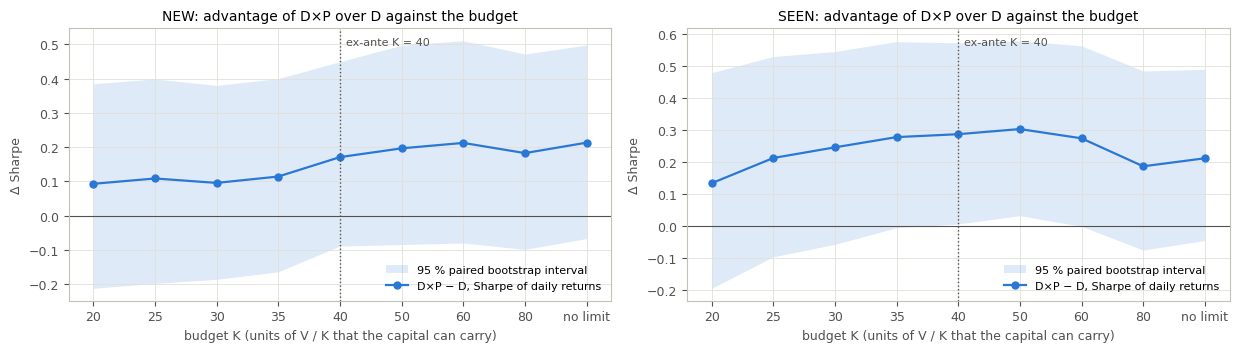

In [9]:
SWEEP = {}
for grp in GROUPS:
    bk = BOOKS[grp]
    for K in BUDGETS + [np.inf]:
        lim = GROSS_LIMIT if np.isfinite(K) else np.inf
        Kx = K if np.isfinite(K) else K_BUDGET
        rr = {r: simulate(bk, bk.sizes(r), K=Kx, gross_limit=lim) for r in ["D", "DxP"]}
        d = deltas({r: rr[r]["ret"] for r in rr}, [("DxP", "D")]).iloc[0]
        SWEEP[(grp, "no limit" if not np.isfinite(K) else int(K))] = {
            "Sharpe D": sharpe(rr["D"]["ret"]), "Sharpe D×P": sharpe(rr["DxP"]["ret"]), "D×P − D": d["Δ Sharpe"],
            "CI low": d["CI low"], "CI high": d["CI high"], "P(Δ > 0)": d["P(Δ > 0)"],
            "D cut by budget": metrics(rr["D"])["cut by budget"], "D×P cut by budget": metrics(rr["DxP"])["cut by budget"],
            "exposure D": metrics(rr["D"])["exposure"], "exposure D×P": metrics(rr["DxP"])["exposure"]}
SWEEP = pd.DataFrame(SWEEP).T
SWEEP.index.names = ["group", "K (units)"]
display(SWEEP.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
for ax, grp in zip(axes, GROUPS):
    t = SWEEP.loc[grp]
    xs = np.arange(len(t))
    ax.fill_between(xs, t["CI low"].astype(float), t["CI high"].astype(float), color=COL["DxP"], alpha=0.15, lw=0,
                    label="95 % paired bootstrap interval")
    ax.plot(xs, t["D×P − D"].astype(float), color=COL["DxP"], marker="o", ms=5, label="D×P − D, Sharpe of daily returns")
    ax.axhline(0, color=INK2, lw=0.8)
    kx = list(t.index).index(K_BUDGET)
    ax.axvline(kx, color=INK2, ls=":", lw=1)
    ax.annotate(f"ex-ante K = {K_BUDGET}", (kx, ax.get_ylim()[1]), xytext=(4, -12), textcoords="offset points", fontsize=8, color=INK2)
    ax.set_xticks(xs); ax.set_xticklabels([str(k) for k in t.index])
    ax.set_xlabel("budget K (units of V / K that the capital can carry)"); ax.set_ylabel("Δ Sharpe")
    ax.set_title(f"{grp}: advantage of D×P over D against the budget")
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

### 5.4 Costs: slippage, the cost at which the advantage disappears, and short borrowing

Slippage of `c` bps per fill is added to the 5 bps fee for every variant (the whole simulation is re-run, because costs change `V`
and therefore later sizes). The break-even cost is where the point estimate of `D×P − D` crosses zero (linear interpolation on the
grid); the same is shown for each variant's own Sharpe, because an advantage that survives a cost at which the portfolio itself
loses money is irrelevant. The last table charges 10 % or 20 % a year on the notional of short positions (SuperTrend only).

Sharpe U  Sharpe D  Sharpe P  Sharpe DxP  D×P − D  CI low  CI high  P(Δ > 0)  turnover D  turnover DxP
group slippage bps / fill                                                                                                        
NEW   0                       0.744     0.758     0.905       0.929    0.171  -0.089    0.450     0.895      53.928        50.183
      2                       0.707     0.717     0.875       0.895    0.179  -0.081    0.460     0.906      53.729        50.155
      5                       0.651     0.655     0.830       0.845    0.190  -0.071    0.475     0.914      53.419        50.108
      10                      0.558     0.553     0.754       0.762    0.210  -0.057    0.498     0.930      52.872        50.013
      15                      0.465     0.450     0.678       0.679    0.229  -0.040    0.521     0.944      52.290        49.898
      20                      0.372     0.347     0.603       0.596    0.248  -0.024    0.543     0.958      51.673        49.760
      30                      0.186     0.143     0.452       0.430    0.287   0.010    0.593     0.980      50.354        49.415
      40                      0.001    -0.061     0.301       0.264    0.326   0.040    0.639     0.990      48.945        48.977
      50                     -0.185    -0.265     0.151       0.100    0.365   0.069    0.684     0.995      47.479        48.447
SEEN  0                       1.147     1.242     1.354       1.530    0.288   0.008    0.573     0.980      76.150        75.346
      2                       1.097     1.185     1.314       1.482    0.297   0.017    0.584     0.984      75.898        75.232
      5                       1.023     1.098     1.254       1.410    0.311   0.030    0.599     0.989      75.501        75.051
      10                      0.899     0.954     1.154       1.289    0.335   0.051    0.625     0.991      74.790        74.726
      15                      0.775     0.810     1.053       1.168    0.358   0.073    0.651     0.994      74.020        74.370
      20                      0.650     0.665     0.953       1.047    0.382   0.095    0.680     0.995      73.193        73.982
      30                      0.402     0.377     0.752       0.806    0.429   0.138    0.732     0.998      71.387        73.107
      40                      0.154     0.090     0.552       0.566    0.477   0.180    0.788     0.999      69.417        72.105
      50                     -0.093    -0.197     0.351       0.327    0.524   0.225    0.840     1.000      67.344        70.987

Slippage (bps per fill, on top of 5 bps) at which each quantity crosses zero (NaN = no crossing within 0–50 bps):


,D×P − D point estimate falls to 0,D×P − D lower 95 % bound rises above 0,Sharpe U falls to 0,Sharpe D falls to 0,Sharpe P falls to 0,Sharpe DxP falls to 0
NEW,NaN,27.1,40.0,37.0,NaN,NaN
SEEN,NaN,NaN,46.2,43.1,NaN,NaN


Borrowing cost on short notional (per year):


Sharpe D  Sharpe D×P  D×P − D  CI low  CI high
NEW  0%      0.758       0.929    0.171  -0.089    0.450
     10%     0.698       0.873    0.175  -0.088    0.456
     20%     0.638       0.816    0.178  -0.087    0.463
SEEN 0%      1.242       1.530    0.288   0.008    0.573
     10%     1.164       1.458    0.294   0.013    0.581
     20%     1.086       1.386    0.300   0.019    0.587

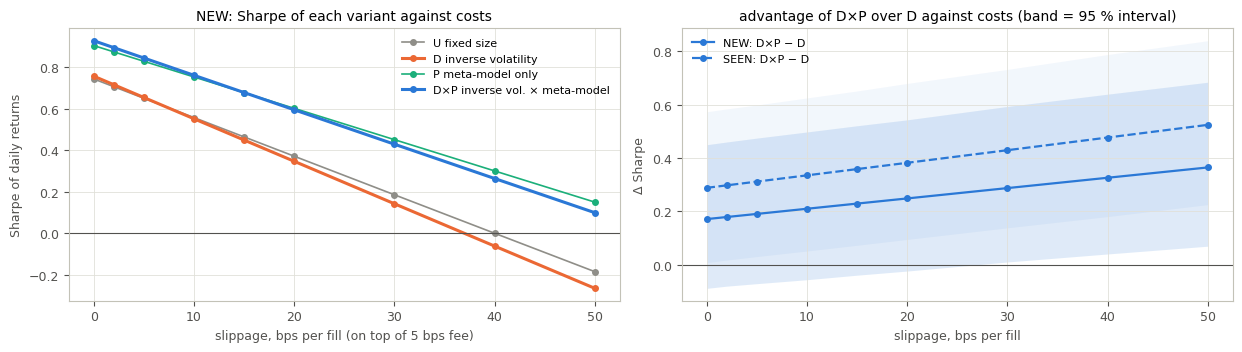

In [10]:
def crossing(xs, ys, direction="down"):
    # first slippage at which ys crosses zero (linear interpolation): "down" = from > 0 to <= 0, "up" = from <= 0 to > 0;
    # NaN = no crossing on the grid (the sign at 0 bps holds up to 50 bps)
    xs, ys = np.asarray(xs, float), np.asarray(ys, float)
    if direction == "up":
        ys = -ys
    for i in range(1, len(xs)):
        if ys[i - 1] > 0 >= ys[i]:
            return xs[i - 1] + (xs[i] - xs[i - 1]) * ys[i - 1] / (ys[i - 1] - ys[i])
    return np.nan


COST, COST_SERIES = {}, {}
for grp in GROUPS:
    bk = BOOKS[grp]
    for c in SLIPPAGE_BPS:
        rr = {r: simulate(bk, bk.sizes(r), cost_bps=FEE_BPS + c) for r in RULES}
        COST_SERIES[(grp, c)] = {r: rr[r]["ret"] for r in RULES}
        d = deltas(COST_SERIES[(grp, c)], [("DxP", "D")]).iloc[0]
        COST[(grp, c)] = {**{f"Sharpe {r}": sharpe(rr[r]["ret"]) for r in RULES}, "D×P − D": d["Δ Sharpe"], "CI low": d["CI low"],
                          "CI high": d["CI high"], "P(Δ > 0)": d["P(Δ > 0)"],
                          **{f"turnover {r}": metrics(rr[r])["turnover (x V / yr)"] for r in ["D", "DxP"]}}
COST = pd.DataFrame(COST).T
COST.index.names = ["group", "slippage bps / fill"]
display(COST.round(3))
BREAK = {}
for grp in GROUPS:
    t = COST.loc[grp]
    BREAK[grp] = {"D×P − D point estimate falls to 0": crossing(t.index, t["D×P − D"]),
                  "D×P − D lower 95 % bound rises above 0": crossing(t.index, t["CI low"], "up"),
                  **{f"Sharpe {r} falls to 0": crossing(t.index, t[f"Sharpe {r}"]) for r in RULES}}
print("Slippage (bps per fill, on top of 5 bps) at which each quantity crosses zero (NaN = no crossing within 0–50 bps):")
display(pd.DataFrame(BREAK).T.round(1))

BORROW = {}
for grp in GROUPS:
    bk = BOOKS[grp]
    for b in BORROW_ANN:
        rr = {r: simulate(bk, bk.sizes(r), borrow_ann=b)["ret"] for r in ["D", "DxP"]}
        d = deltas(rr, [("DxP", "D")]).iloc[0]
        BORROW[(grp, f"{b:.0%}")] = {"Sharpe D": sharpe(rr["D"]), "Sharpe D×P": sharpe(rr["DxP"]), "D×P − D": d["Δ Sharpe"],
                                     "CI low": d["CI low"], "CI high": d["CI high"]}
print("Borrowing cost on short notional (per year):")
display(pd.DataFrame(BORROW).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
t = COST.loc["NEW"]
for r in RULES:
    axes[0].plot(t.index, t[f"Sharpe {r}"], color=COL[r], marker="o", ms=4, lw=2.2 if r in ("D", "DxP") else 1.2, label=RULE_NAME[r])
axes[0].axhline(0, color=INK2, lw=0.8)
axes[0].set_xlabel("slippage, bps per fill (on top of 5 bps fee)"); axes[0].set_ylabel("Sharpe of daily returns")
axes[0].set_title("NEW: Sharpe of each variant against costs"); axes[0].legend(fontsize=8)
for grp, ls in [("NEW", "-"), ("SEEN", "--")]:
    t = COST.loc[grp]
    axes[1].plot(t.index, t["D×P − D"], color=COL["DxP"], ls=ls, marker="o", ms=4, label=f"{grp}: D×P − D")
    axes[1].fill_between(t.index, t["CI low"].astype(float), t["CI high"].astype(float), color=COL["DxP"],
                         alpha=0.15 if grp == "NEW" else 0.06, lw=0)
axes[1].axhline(0, color=INK2, lw=0.8)
axes[1].set_xlabel("slippage, bps per fill"); axes[1].set_ylabel("Δ Sharpe")
axes[1].set_title("advantage of D×P over D against costs (band = 95 % interval)"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 6. Question 2 — where does the difference come from?

### 6.1 Attribution by strategy and year, from the positions actually allocated

Every daily return of the shared portfolio is the sum of the strategies' contributions, `PnL(strategy, day) / V(previous day end)`,
with the PnL of the positions the portfolio really held (after the budget). Summing a strategy's daily contributions over a calendar
year gives its contribution in percentage points of return; the difference `D×P − D` of these sums attributes the difference in
(arithmetic) return. The second table splits the difference into the trades the meta-model **rejected** (`P = 0`: `D` traded them,
`D×P` did not, so the entry is minus what `D` earned on them) and the trades **both** took (the re-sizing). Years are calendar
years by the day of the PnL (2019 starts in March, 2026 ends on 18 November).

NEW: contribution to the portfolio's return, percentage points (sum of daily contributions), by strategy and year


2019  2020  2021  2022  2023  2024  2025  2026  total
variant strategy                                                         
D       DONCHIAN     0.0   0.9  14.7  -5.6  -1.7  12.7   8.0   2.3   31.4
        RSI         -2.8  -3.3   0.3  -5.3  -9.8  -0.2   2.2   0.1  -18.9
        SUPERTREND   0.0   6.9  15.1  18.4  -3.5  16.6  22.2  18.9   94.6
        TIS          0.0   0.0  14.5  -1.3   9.0  20.4  -2.2  -1.7   38.6
        ALL         -2.8   4.5  44.6   6.2  -6.0  49.5  30.1  19.6  145.7
D×P     DONCHIAN     0.0   2.4  13.2  -7.2   3.4   6.8   0.6   1.7   21.0
        RSI         -5.0  11.1  -2.7  -2.1  -2.8   1.3  -1.5  -0.0   -1.7
        SUPERTREND   0.0  20.9  37.2  17.4 -11.7  17.8  41.4  25.7  148.6
        TIS          0.0   0.0  29.3  -4.3   4.7  16.2  -4.3  -2.0   39.6
        ALL         -5.0  34.3  77.0   3.9  -6.4  42.1  36.2  25.3  207.5
D×P − D DONCHIAN     0.0   1.5  -1.4  -1.6   5.1  -5.9  -7.5  -0.6  -10.5
        RSI         -2.2  14.4  -3.0   3.2   7.0   1.5  -3.6  -0.1   17.1
        SUPERTREND   0.0  14.0  22.1  -0.9  -8.2   1.2  19.2   6.8   54.1
        TIS          0.0   0.0  14.8  -2.9  -4.3  -4.2  -2.0  -0.3    1.0
        ALL         -2.2  29.9  32.4  -2.3  -0.4  -7.4   6.1   5.7   61.8

NEW: D×P − D split into filtering and re-sizing, percentage points over the whole period


,rejected trades (−D's PnL on them),accepted trades (re-sizing),D×P − D
RSI,8.2,8.9,17.1
DONCHIAN,1.8,-12.3,-10.5
TIS,-5.9,7.0,1.0
SUPERTREND,-9.5,63.6,54.1
ALL,-5.4,67.2,61.8


SEEN: contribution to the portfolio's return, percentage points (sum of daily contributions), by strategy and year


2019  2020   2021  2022  2023  2024  2025  2026  total
variant strategy                                                          
D       DONCHIAN     0.0  22.3   24.6   7.0   9.9  12.6   1.2   4.6   82.2
        RSI          0.7  13.2   16.0  -1.6   3.3  10.0   2.2   3.1   47.0
        SUPERTREND   0.0  13.0    3.7   5.3  12.6  12.5   9.9  14.9   71.9
        TIS          0.0   0.0   22.9  -2.2   5.6   8.7  -5.2  -2.3   27.5
        ALL          0.7  48.5   67.2   8.5  31.4  43.8   8.2  20.3  228.6
D×P     DONCHIAN     0.0  28.8   21.7   7.4  10.9  10.7  -0.2   5.8   85.1
        RSI          4.3  23.2   54.2  -0.2   7.1   9.0  -0.4   1.5   98.7
        SUPERTREND   0.0  19.2   19.8  11.4   9.9  12.4  17.9  12.1  102.6
        TIS          0.0   0.0   41.3  -6.2   5.4  17.7  -7.6  -1.9   48.7
        ALL          4.3  71.2  136.9  12.3  33.4  49.9   9.7  17.6  335.2
D×P − D DONCHIAN     0.0   6.5   -2.9   0.3   1.0  -1.9  -1.4   1.3    2.9
        RSI          3.6  10.0   38.2   1.4   3.8  -1.0  -2.6  -1.6   51.7
        SUPERTREND   0.0   6.2   16.0   6.1  -2.7  -0.1   7.9  -2.9   30.7
        TIS          0.0   0.0   18.3  -4.0  -0.2   9.1  -2.4   0.4   21.2
        ALL          3.6  22.7   69.7   3.8   1.9   6.0   1.5  -2.7  106.5

SEEN: D×P − D split into filtering and re-sizing, percentage points over the whole period


,rejected trades (−D's PnL on them),accepted trades (re-sizing),D×P − D
RSI,-2.5,54.2,51.7
DONCHIAN,-2.6,5.5,2.9
TIS,0.7,20.6,21.2
SUPERTREND,5.4,25.2,30.7
ALL,0.9,105.6,106.5


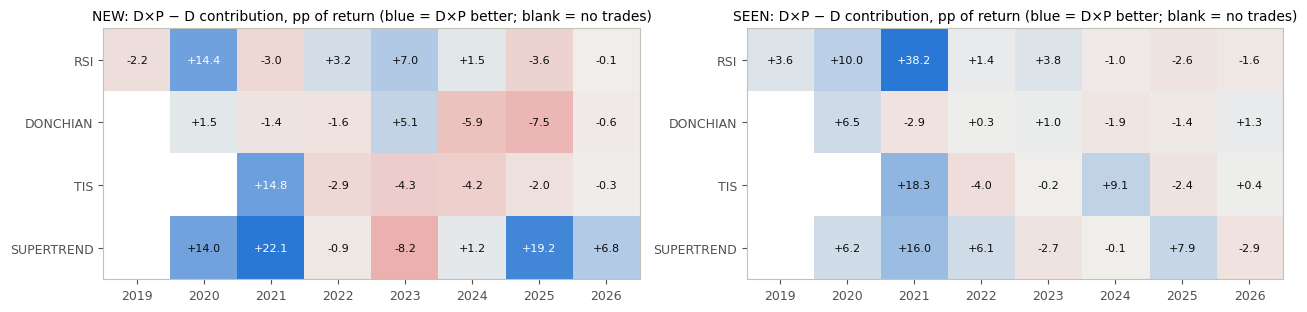

In [11]:
def contributions(res):
    c = res["pnl_day"] / res["v_day"][:-1, None]           # (days, labels) in return units
    df = pd.DataFrame(c, index=CAL)
    out = {}
    for si, s in enumerate(SS):
        out[(s, "rejected by the model")] = df[2 * si]
        out[(s, "accepted by the model")] = df[2 * si + 1]
    return pd.DataFrame(out)


ATTR = {}
for grp in GROUPS:
    cD, cX = contributions(MAIN[grp]["D"]), contributions(MAIN[grp]["DxP"])
    yD = cD.T.groupby(level=0).sum().T.groupby(CAL.year).sum() * 100
    yX = cX.T.groupby(level=0).sum().T.groupby(CAL.year).sum() * 100
    ATTR[grp] = {"D": yD, "DxP": yX, "cD": cD, "cX": cX}
    tab = pd.concat({"D": yD.T, "D×P": yX.T, "D×P − D": (yX - yD).T}, names=["variant", "strategy"])
    tab["total"] = tab.sum(1)
    tab = pd.concat([tab, pd.concat({v: tab.xs(v, level="variant").sum().to_frame("ALL").T for v in ["D", "D×P", "D×P − D"]},
                                    names=["variant", "strategy"])])
    print(f"{grp}: contribution to the portfolio's return, percentage points (sum of daily contributions), by strategy and year")
    display(tab.reindex(["D", "D×P", "D×P − D"], level=0).round(1))
    split = pd.DataFrame({
        "rejected trades (−D's PnL on them)": -cD.xs("rejected by the model", axis=1, level=1).sum() * 100,
        "accepted trades (re-sizing)": (cX.xs("accepted by the model", axis=1, level=1).sum()
                                        - cD.xs("accepted by the model", axis=1, level=1).sum()) * 100})
    split["D×P − D"] = split.sum(1)
    split.loc["ALL"] = split.sum()
    print(f"{grp}: D×P − D split into filtering and re-sizing, percentage points over the whole period")
    display(split.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for ax, grp in zip(axes, GROUPS):
    M = (ATTR[grp]["DxP"] - ATTR[grp]["D"]).T.reindex(SS)
    M = M.mask((ATTR[grp]["D"].T.reindex(SS) == 0) & (ATTR[grp]["DxP"].T.reindex(SS) == 0))   # no trades: blank
    v = np.nanmax(np.abs(M.to_numpy())) or 1
    ax.imshow(M.to_numpy(), cmap=DIVERGING, vmin=-v, vmax=v, aspect="auto")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
    ax.grid(False)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M.iat[i, j]):
                ax.text(j, i, f"{M.iat[i, j]:+.1f}", ha="center", va="center", fontsize=8,
                        color="white" if abs(M.iat[i, j]) > 0.65 * v else INK)
    ax.set_title(f"{grp}: D×P − D contribution, pp of return (blue = D×P better; blank = no trades)")
fig.tight_layout(); plt.show()

### 6.2 Does the result depend on SuperTrend (or on any one strategy)?

Three portfolios per strategy, all with the same budget and rules: **without the strategy** (its trades removed from both variants,
the capital shared by the other three); **meta-model only on that strategy** (`D×P` sizes for its trades, `D` for the others) and
**meta-model on all but that strategy**, both against the full `D` portfolio.

In [12]:
STRAT_ROB = {}
for grp in GROUPS:
    bk = BOOKS[grp]
    wD, wX = bk.sizes("D"), bk.sizes("DxP")
    base = MAIN[grp]["D"]["ret"]
    for s in SS:
        own = bk.strat == SS_IX[s]
        sub = bk.subset(~own)
        r_wo = {r: simulate(sub, sub.sizes(r))["ret"] for r in ["D", "DxP"]}
        d_wo = deltas(r_wo, [("DxP", "D")]).iloc[0]
        r_only = simulate(bk, np.where(own, wX, wD))["ret"]
        r_but = simulate(bk, np.where(own, wD, wX))["ret"]
        d_only = deltas({"only": r_only, "D": base}, [("only", "D")]).iloc[0]
        d_but = deltas({"but": r_but, "D": base}, [("but", "D")]).iloc[0]
        STRAT_ROB[(grp, s)] = {"without it: Sharpe D": sharpe(r_wo["D"]), "without it: Sharpe D×P": sharpe(r_wo["DxP"]),
                               "without it: D×P − D": fmt(d_wo), "meta only on it − D": fmt(d_only),
                               "meta on all but it − D": fmt(d_but)}
STRAT_ROB = pd.DataFrame(STRAT_ROB).T
STRAT_ROB.index.names = ["group", "strategy"]
for grp in GROUPS:
    print(f"{grp}: full portfolio D×P − D = {fmt(MAIN_DELTA[grp].iloc[0])}")
display(STRAT_ROB.round(3))

NEW: full portfolio D×P − D = +0.171 [-0.09, +0.45]
SEEN: full portfolio D×P − D = +0.288 [+0.01, +0.57]*


without it: Sharpe D without it: Sharpe D×P     without it: D×P − D     meta only on it − D  meta on all but it − D
group strategy                                                                                                                      
NEW   RSI                    0.950178               1.095316   +0.145 [-0.13, +0.42]   +0.038 [-0.06, +0.13]   +0.121 [-0.13, +0.38]
      DONCHIAN               0.789945                0.97794   +0.188 [-0.14, +0.52]   +0.013 [-0.03, +0.06]   +0.166 [-0.09, +0.44]
      TIS                    0.678188               0.905477   +0.227 [-0.04, +0.51]   +0.036 [-0.06, +0.15]   +0.161 [-0.08, +0.42]
      SUPERTREND             0.605193               0.615198   +0.010 [-0.28, +0.32]   +0.118 [-0.09, +0.34]   +0.078 [-0.06, +0.24]
SEEN  RSI                    1.206567               1.287705   +0.081 [-0.21, +0.37]  +0.233 [+0.08, +0.41]*   +0.075 [-0.19, +0.36]
      DONCHIAN               1.011475               1.362991  +0.352 [+0.03, +0.68]*   +0.040 [-0.03, +0.11]   +0.258 [-0.02, +0.54]
      TIS                    1.261965               1.455428   +0.193 [-0.10, +0.51]   +0.046 [-0.03, +0.12]   +0.255 [-0.01, +0.54]
      SUPERTREND             1.457356               1.790299  +0.333 [+0.14, +0.56]*   -0.001 [-0.25, +0.27]  +0.322 [+0.15, +0.51]*

### 6.3 Does it depend on a single year?

The Sharpe ratio of each variant within each calendar year (from that year's daily returns), and the full-period `D×P − D` with
one year left out of both return series at a time (paired monthly block bootstrap on the remaining months).

In [13]:
YEARS = sorted(set(CAL.year))
YEAR_ROB = {}
for grp in GROUPS:
    rD, rX = pd.Series(MAIN[grp]["D"]["ret"], index=CAL), pd.Series(MAIN[grp]["DxP"]["ret"], index=CAL)
    for y in YEARS:
        m = CAL.year != y
        lab = pd.factorize(MONTHS[m])[0]
        d = deltas({"DxP": rX[m].to_numpy(), "D": rD[m].to_numpy()}, [("DxP", "D")], labels=lab).iloc[0]
        YEAR_ROB[(grp, y)] = {"days": int((~m).sum()), "Sharpe D in year": sharpe(rD[~m]), "Sharpe D×P in year": sharpe(rX[~m]),
                              "Δ in year": sharpe(rX[~m]) - sharpe(rD[~m]),
                              "return D in year": (1 + rD[~m]).prod() - 1, "return D×P in year": (1 + rX[~m]).prod() - 1,
                              "full period without this year: D×P − D": fmt(d), "_d": d["Δ Sharpe"], "_lo": d["CI low"]}
YEAR_ROB = pd.DataFrame(YEAR_ROB).T
YEAR_ROB.index.names = ["group", "year"]
display(YEAR_ROB.drop(columns=["_d", "_lo"]).round(3))
for grp in GROUPS:
    t = YEAR_ROB.loc[grp]
    print(f"{grp}: leave-one-year-out D×P − D ranges {t['_d'].min():+.3f} … {t['_d'].max():+.3f}; lower CI bound > 0 in "
          f"{int((t['_lo'] > 0).sum())} of {len(t)}; D×P beats D within {int((t['Δ in year'] > 0).sum())} of {len(t)} years")

# concentration in a few months: the monthly sum of the daily return difference, and D×P − D without the best months
MONTH_ROB = {}
for grp in GROUPS:
    rD, rX = MAIN[grp]["D"]["ret"], MAIN[grp]["DxP"]["ret"]
    dm = pd.Series(rX - rD).groupby(MONTHS).sum()
    best = dm.sort_values(ascending=False).index
    row = {"total return difference (pp)": dm.sum() * 100}
    for n in (1, 3, 6):
        keep = ~np.isin(MONTHS, best[:n])
        lab = pd.factorize(MONTHS[keep])[0]
        d = deltas({"DxP": rX[keep], "D": rD[keep]}, [("DxP", "D")], labels=lab).iloc[0]
        row[f"best {n} month(s): share of the difference"] = dm.loc[best[:n]].sum() / dm.sum()
        row[f"D×P − D without best {n}"] = fmt(d)
    row["best months"] = ", ".join(pd.Period(CAL[MONTHS == k][0], "M").strftime("%Y-%m") for k in best[:3])
    MONTH_ROB[grp] = row
print("Concentration of the difference in a few calendar months:")
pd.DataFrame(MONTH_ROB).T

days Sharpe D in year Sharpe D×P in year Δ in year return D in year return D×P in year full period without this year: D×P − D
group year                                                                                                                              
NEW   2019  306        -1.553624          -1.906422 -0.352797        -0.028218          -0.049638                  +0.190 [-0.09, +0.47]
      2020  366         0.308327           1.522551  1.214224         0.034841           0.374773                  +0.060 [-0.21, +0.36]
      2021  365         1.429941           1.768662  0.338721         0.487533           0.964745                  +0.113 [-0.15, +0.45]
      2022  365         0.236478           0.128137 -0.108341         0.028499          -0.006664                  +0.215 [-0.07, +0.52]
      2023  365        -0.223571           -0.20644  0.017131          -0.0909          -0.104939                  +0.194 [-0.08, +0.50]
      2024  366         1.570356            1.43843 -0.131926         0.562051           0.459938                  +0.249 [-0.05, +0.55]
      2025  365           1.1779           1.460367  0.282467         0.309132            0.39307                  +0.170 [-0.10, +0.46]
      2026  322          0.88846           1.022007  0.133548         0.184299            0.24502                  +0.176 [-0.11, +0.46]
SEEN  2019  306         0.152844           0.678079  0.525235          0.00567           0.041435                  +0.291 [-0.00, +0.59]
      2020  366         1.981132           2.646195  0.665062         0.576828           0.966061                  +0.246 [-0.08, +0.56]
      2021  365         2.298115           3.262968  0.964853         0.876613           2.600295                  +0.101 [-0.21, +0.41]
      2022  365         0.333863           0.411944  0.078081         0.054458           0.082213                 +0.318 [+0.05, +0.58]*
      2023  365          1.17801           1.078563 -0.099447         0.322158           0.332543                 +0.351 [+0.06, +0.67]*
      2024  366         1.649457           1.843823  0.194366         0.496335            0.58727                  +0.311 [-0.01, +0.64]
      2025  365          0.39243           0.396416  0.003986         0.062109           0.069705                 +0.323 [+0.04, +0.62]*
      2026  322         1.069913           0.851206 -0.218707         0.200915           0.163956                 +0.342 [+0.03, +0.64]*

NEW: leave-one-year-out D×P − D ranges +0.060 … +0.249; lower CI bound > 0 in 0 of 8; D×P beats D within 5 of 8 years
SEEN: leave-one-year-out D×P − D ranges +0.101 … +0.351; lower CI bound > 0 in 4 of 8; D×P beats D within 6 of 8 years
Concentration of the difference in a few calendar months:


,total return difference (pp),best 1 month(s): share of the difference,D×P − D without best 1,best 3 month(s): share of the difference,D×P − D without best 3,best 6 month(s): share of the difference,D×P − D without best 6,best months
NEW,61.799454,0.201397,"+0.134 [-0.14, +0.40]",0.574514,"+0.060 [-0.18, +0.33]",0.937241,"-0.033 [-0.26, +0.23]","2021-03, 2021-02, 2020-08"
SEEN,106.528661,0.173987,"+0.249 [-0.05, +0.54]",0.467861,"+0.141 [-0.13, +0.39]",0.689897,"+0.060 [-0.21, +0.31]","2021-02, 2021-01, 2022-05"


### 6.4 Does it depend on differences in exposure?

A constant difference in exposure does not change a Sharpe ratio, but `D×P` does not scale `D` by a constant: it moves capital
between strategies and windows (the test-period probabilities sit above the training ones for some strategies and below for others),
and it concentrates capital in fewer trades. Three views:

* realised exposure of each variant, in total and by strategy (time-weighted gross market value / `V`);
* a **non-tradable** diagnostic `D × m̄`: each trade of `D` multiplied by the **mean** `D×P / D` multiplier of its strategy and window,
  i.e. `D×P`'s allocation across strategies and windows with no selection inside a window (it uses the window's realised mean, so it
  could not be traded — it only decomposes the effect);
* a **permutation null** (the source's permutation test, re-run through the portfolio): the meta-model multipliers are shuffled among
  the trades of the same strategy and window (1 000 shuffles), so each window keeps its mean multiplier, its share of rejected trades
  and its dispersion, but the link between a trade and its probability is destroyed. If the observed `D×P − D` is no larger than this
  null, the advantage comes from exposure and allocation, not from the model's ranking of trades.

exposure (all) exposure RSI exposure DONCHIAN exposure TIS exposure SUPERTREND return / exposure    Sharpe                 Δ vs D
NEW  D inverse volatility                                0.358791      0.01483          0.031482     0.039348            0.273131          0.525528  0.757819                    NaN
     D×P inverse vol. × meta-model                       0.384389     0.014094          0.026788      0.03788            0.305626          0.698624  0.928681                    NaN
     D × m̄ (window-mean multiplier, non-tradable)            NaN          NaN               NaN          NaN                 NaN               NaN  0.770593  +0.013 [-0.10, +0.15]
SEEN D inverse volatility                                0.453664     0.024813          0.040233     0.048302            0.340316          0.652291  1.242347                    NaN
     D×P inverse vol. × meta-model                       0.484461      0.02664          0.037831     0.053142            0.366848          0.895436  1.530392                    NaN
     D × m̄ (window-mean multiplier, non-tradable)            NaN          NaN               NaN          NaN                 NaN               NaN  1.260047  +0.018 [-0.10, +0.12]

Permutation null of D×P − D (1000 shuffles of the meta-model multiplier within strategy × window):


,observed,null mean,null p95,p (one-sided),tilt,observed − null mean (ranking part)
NEW,0.171,-0.033,0.136,0.032,0.013,0.203
SEEN,0.288,-0.060,0.100,0.001,0.018,0.348


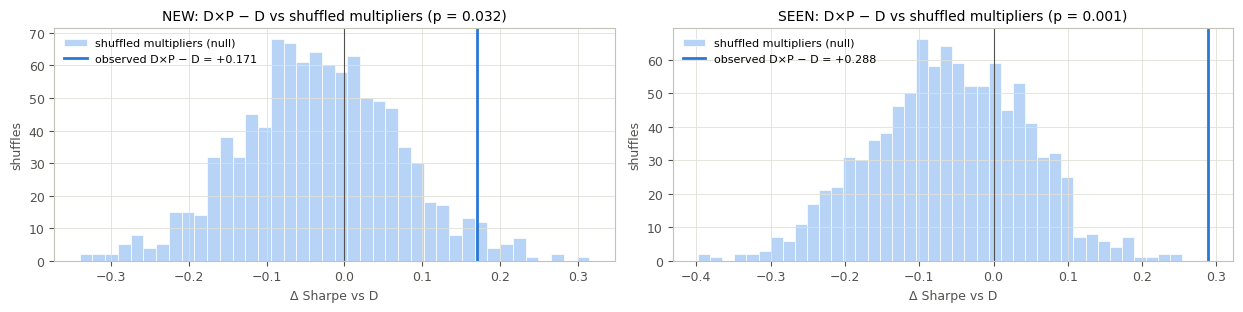

In [14]:
EXPO, PERM = {}, {}
rng = np.random.default_rng(SEED)
for grp in GROUPS:
    bk = BOOKS[grp]
    wD, wX = bk.sizes("D"), bk.sizes("DxP")
    ratio = wX / wD
    keys = pd.Series(bk.strat.astype(str)) + "|" + pd.Series(bk.window.astype(str))
    groups = [np.flatnonzero(keys.to_numpy() == k) for k in keys.unique()]
    mbar = np.empty_like(ratio)
    for idx in groups:
        mbar[idx] = ratio[idx].mean()
    r_tilt = simulate(bk, np.minimum(wD * mbar, SIZE_CAP))["ret"]
    obs = sharpe(MAIN[grp]["DxP"]["ret"]) - sharpe(MAIN[grp]["D"]["ret"])
    null = np.empty(N_PERM)
    for i in range(N_PERM):
        rp = ratio.copy()
        for idx in groups:
            rp[idx] = ratio[rng.permutation(idx)]
        null[i] = sharpe(simulate(bk, np.minimum(wD * rp, SIZE_CAP))["ret"]) - sharpe(MAIN[grp]["D"]["ret"])
    PERM[grp] = {"observed": obs, "null": null}
    for r in ["D", "DxP"]:
        res = MAIN[grp][r]
        g_s = res["gross"][:-1].reshape(-1, len(SS), 2).sum(2) / res["V"][:-1, None]
        EXPO[(grp, RULE_NAME[r])] = {"exposure (all)": metrics(res)["exposure"],
                                     **{f"exposure {s}": g_s[:, i].mean() for i, s in enumerate(SS)},
                                     "return / exposure": metrics(res)["return / exposure"], "Sharpe": metrics(res)["Sharpe"]}
    d_tilt = deltas({"tilt": r_tilt, "D": MAIN[grp]["D"]["ret"]}, [("tilt", "D")]).iloc[0]
    EXPO[(grp, "D × m̄ (window-mean multiplier, non-tradable)")] = {"Sharpe": sharpe(r_tilt), "Δ vs D": fmt(d_tilt)}
    PERM[grp].update({"null mean": null.mean(), "null p95": np.quantile(null, 0.95),
                      "p (one-sided)": (1 + (null >= obs).sum()) / (1 + N_PERM), "tilt": d_tilt["Δ Sharpe"]})
display(pd.DataFrame(EXPO).T.round(3))
PERM_TAB = pd.DataFrame({g: {k: v for k, v in PERM[g].items() if k != "null"} for g in GROUPS}).T
PERM_TAB["observed − null mean (ranking part)"] = PERM_TAB["observed"] - PERM_TAB["null mean"]
print(f"Permutation null of D×P − D ({N_PERM} shuffles of the meta-model multiplier within strategy × window):")
display(PERM_TAB.astype(float).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.2))
for ax, grp in zip(axes, GROUPS):
    ax.hist(PERM[grp]["null"], bins=40, color="#b7d3f6", edgecolor="white", lw=0.5, label="shuffled multipliers (null)")
    ax.axvline(PERM[grp]["observed"], color=COL["DxP"], lw=2, label=f"observed D×P − D = {PERM[grp]['observed']:+.3f}")
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlabel("Δ Sharpe vs D"); ax.set_ylabel("shuffles")
    ax.set_title(f"{grp}: D×P − D vs shuffled multipliers (p = {PERM[grp]['p (one-sided)']:.3f})")
    ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

## 7. Summary: comparison table and equity curves

Shared portfolio, ex-ante budget, 5 bps per fill, daily returns 2019-03-01 → 2026-11-18. Intervals are paired monthly block
bootstrap 95 % intervals.

ann. return  Sharpe  max DD  exposure  turnover (x V / yr)  trades  cut by budget Δ Sharpe vs D [95 % CI]
group variant                                                                                                                                 
NEW   U fixed size                         0.202   0.744  -0.355     0.408               62.158    9467          0.119   -0.013 [-0.23, +0.23]
      D inverse volatility                 0.171   0.758  -0.314     0.359               53.928    9435          0.123                     NaN
      P meta-model only                    0.311   0.905  -0.346     0.460               59.236    7833          0.203   +0.147 [-0.20, +0.51]
      D×P inverse vol. × meta-model        0.255   0.929  -0.343     0.384               50.183    7940          0.170   +0.171 [-0.09, +0.45]
SEEN  U fixed size                         0.307   1.147  -0.232     0.429               71.042   10675          0.116   -0.096 [-0.29, +0.11]
      D inverse volatility                 0.307   1.242  -0.208     0.454               76.150   10550          0.191                     NaN
      P meta-model only                    0.495   1.354  -0.317     0.493               71.352    9001          0.241   +0.112 [-0.24, +0.47]
      D×P inverse vol. × meta-model        0.483   1.530  -0.243     0.484               75.346    9006          0.277  +0.288 [+0.01, +0.57]*

D×P − D in one place:


,NEW,SEEN
"source, no budget (monthly)","+0.228 [+0.01, +0.47]*","+0.171 [-0.01, +0.37]"
"source, capital replay (monthly)","+0.072 [-0.17, +0.32]","+0.038 [-0.20, +0.31]"
"shared portfolio, ex-ante K = 40","+0.171 [-0.09, +0.45]","+0.288 [+0.01, +0.57]*"
permutation p (strategy × window),0.032,0.001
slippage at which D×P − D falls to 0 (bps/fill),> 50 (no crossing),> 50 (no crossing)
without SuperTrend,"+0.010 [-0.28, +0.32]","+0.333 [+0.14, +0.56]*"
meta only on SuperTrend − D,"+0.118 [-0.09, +0.34]","-0.001 [-0.25, +0.27]"
leave-one-year-out range,+0.060 … +0.249,+0.101 … +0.351


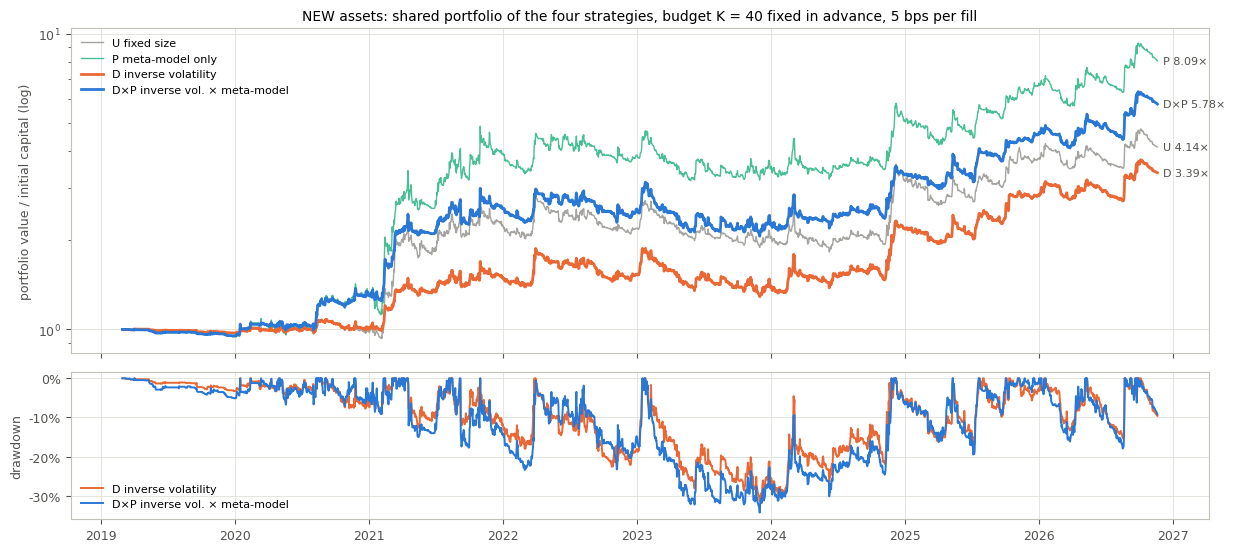

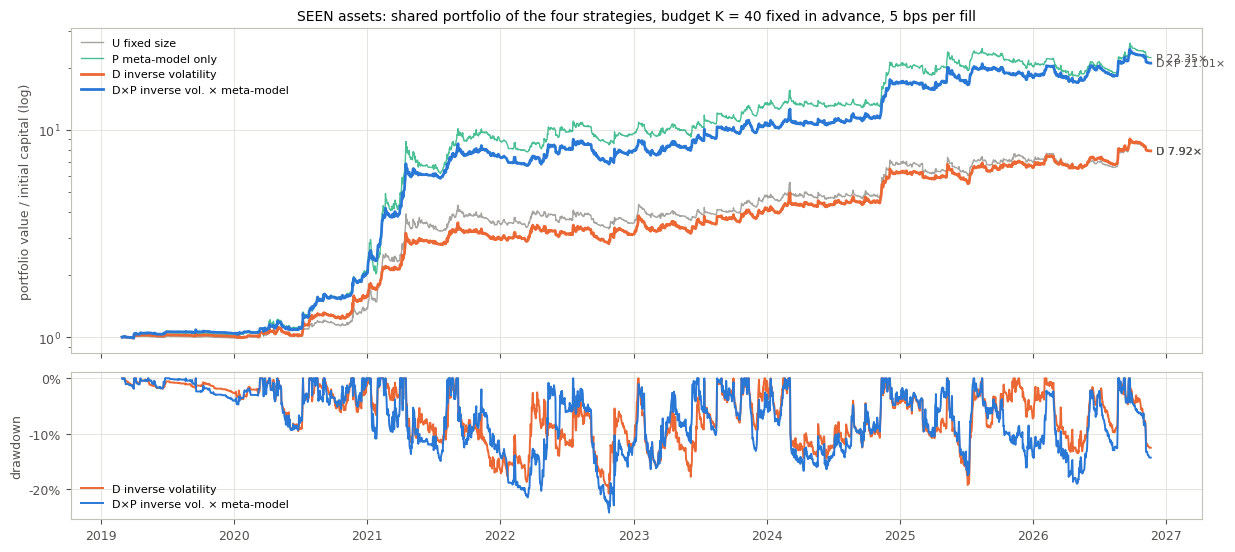

total runtime 0.5 min


In [15]:
rows = []
for grp in GROUPS:
    for r in RULES:
        mt = metrics(MAIN[grp][r])
        row = {"group": grp, "variant": RULE_NAME[r], "ann. return": mt["ann. return"], "Sharpe": mt["Sharpe"],
               "max DD": mt["max DD"], "exposure": mt["exposure"], "turnover (x V / yr)": mt["turnover (x V / yr)"],
               "trades": mt["trades"], "cut by budget": mt["cut by budget"]}
        if r != "D":
            d = deltas({r: MAIN[grp][r]["ret"], "D": MAIN[grp]["D"]["ret"]}, [(r, "D")]).iloc[0]
            row["Δ Sharpe vs D [95 % CI]"] = fmt(d)
        rows.append(row)
SUMMARY = pd.DataFrame(rows).set_index(["group", "variant"])
display(SUMMARY.round(3))

KEY = {}
for grp in GROUPS:
    KEY[grp] = {"source, no budget (monthly)": fmt(qe.paired_sharpe_table(REPRO[grp]["no budget"], [("DxP", "D")]).iloc[0]),
                "source, capital replay (monthly)": fmt(qe.paired_sharpe_table(REPRO[grp]["capital replay"], [("DxP", "D")]).iloc[0]),
                f"shared portfolio, ex-ante K = {K_BUDGET}": fmt(MAIN_DELTA[grp].iloc[0]),
                "permutation p (strategy × window)": f"{PERM[grp]['p (one-sided)']:.3f}",
                "slippage at which D×P − D falls to 0 (bps/fill)": (f"{BREAK[grp]['D×P − D point estimate falls to 0']:.1f}"
                                                                     if np.isfinite(BREAK[grp]['D×P − D point estimate falls to 0']) else "> 50 (no crossing)"),
                "without SuperTrend": STRAT_ROB.loc[(grp, "SUPERTREND"), "without it: D×P − D"],
                "meta only on SuperTrend − D": STRAT_ROB.loc[(grp, "SUPERTREND"), "meta only on it − D"],
                "leave-one-year-out range": f"{YEAR_ROB.loc[grp, '_d'].min():+.3f} … {YEAR_ROB.loc[grp, '_d'].max():+.3f}"}
print("D×P − D in one place:")
display(pd.DataFrame(KEY))

for grp in GROUPS:
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(12.5, 5.6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
    days = CAL.append(pd.DatetimeIndex([DATA_END]))
    for r in ["U", "P", "D", "DxP"]:
        v = MAIN[grp][r]["v_day"] / MAIN[grp][r]["C0"]
        main_ = r in ("D", "DxP")
        ax.plot(days, v, color=COL[r], lw=2.0 if main_ else 1.0, alpha=1 if main_ else 0.8, label=RULE_NAME[r])
        ax.annotate(f"{r.replace('x', '×')} {v[-1]:.2f}×", (days[-1], v[-1]), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK2)
        if main_:
            ax2.plot(days, v / np.maximum.accumulate(v) - 1, color=COL[r], lw=1.4, label=RULE_NAME[r])
    ax.set_yscale("log"); ax.set_ylabel("portfolio value / initial capital (log)")
    ax.set_title(f"{grp} assets: shared portfolio of the four strategies, budget K = {K_BUDGET} fixed in advance, 5 bps per fill")
    ax.legend(fontsize=8, loc="upper left")
    ax2.set_ylabel("drawdown"); ax2.legend(fontsize=8, loc="lower left")
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    fig.tight_layout(); plt.show()
print(f"total runtime {(time.time() - T0) / 60:.1f} min")

### 7.1 What would a confirmatory test need?

`NEW` has now been examined three times, so the next piece of evidence has to come from data that nobody has looked at: the trades
decided after 2026-11-19. The cell asks how much of it a test of the shared portfolio needs. The bootstrap standard deviation of
`D×P − D` over the 7.7 evaluated years is scaled as `sd × sqrt(7.7 / T)` (Sharpe estimates sharpen with the square root of time;
the 20 assets are strongly correlated, so adding assets helps much less than adding years). Required years `T` for a one-sided 5 %
test: 50 % power (the interval would just exclude zero if the true effect equals the assumed one) and 80 % power. Assumed effects:
the `NEW` estimate, half of it (a usual allowance for an estimate that was selected because it looked good), and the `SEEN` estimate.

In [16]:
from scipy.stats import norm

YEARS_EVAL = len(CAL) / DAYS_PER_YEAR
POWER = {}
for grp in GROUPS:
    B = qe.bootstrap_sharpe(np.vstack([MAIN[grp]["DxP"]["ret"], MAIN[grp]["D"]["ret"]]), MONTHS, n_boot=N_BOOT, seed=SEED)
    sd = float(np.nanstd(B[0] - B[1], ddof=1))
    POWER[grp] = {"Δ estimate": MAIN_DELTA[grp].iloc[0]["Δ Sharpe"], "bootstrap sd of Δ (7.7 years)": sd,
                  "sd of Δ in 1 year of new data": sd * np.sqrt(YEARS_EVAL)}
rows = []
for name, eff in [("NEW estimate", POWER["NEW"]["Δ estimate"]), ("half of the NEW estimate", POWER["NEW"]["Δ estimate"] / 2),
                  ("SEEN estimate", POWER["SEEN"]["Δ estimate"])]:
    sd1 = POWER["NEW"]["sd of Δ in 1 year of new data"]
    rows.append({"assumed true D×P − D": name, "effect": eff,
                 "years for 50 % power": (norm.ppf(0.95) * sd1 / eff) ** 2,
                 "years for 80 % power": ((norm.ppf(0.95) + norm.ppf(0.80)) * sd1 / eff) ** 2})
display(pd.DataFrame(POWER).T.round(3))
print("Years of new data needed by a test of the NEW shared portfolio (one-sided 5 %):")
POWER_TAB = pd.DataFrame(rows).set_index("assumed true D×P − D")
POWER_TAB.round(2)

,Δ estimate,bootstrap sd of Δ (7.7 years),sd of Δ in 1 year of new data
NEW,0.171,0.138,0.383
SEEN,0.288,0.145,0.403


Years of new data needed by a test of the NEW shared portfolio (one-sided 5 %):


,effect,years for 50 % power,years for 80 % power
assumed true D×P − D,,,
NEW estimate,0.17,13.61,31.09
half of the NEW estimate,0.09,54.42,124.37
SEEN estimate,0.29,4.79,10.94


## 8. Conclusions

All figures are copied from the outputs above. `NEW` = the 20 assets no model trained on (9 649 trades), `SEEN` = the 20 training
assets (10 816 trades); daily returns 2019-03-01 → 2026-11-18 (2 820 days); intervals are paired monthly block bootstrap 95 %
intervals.

### 8.1 Reproduction, and what the source's capital replay was measuring

* The source's numbers are reproduced exactly from the cached predictions: without a budget `D` 0.881, `D×P` 1.109,
  **`D×P − D` +0.228 [+0.01, +0.47]**; in the capital replay `D` 0.740, `D×P` 0.812, **+0.072 [−0.17, +0.32]** (`SEEN` +0.171 and
  +0.038).
* The replay's +0.072 depended on an accident of ordering: 75 % of the `NEW` trades enter at the same 4h open as another trade, and
  when the budget bound, the trades that came first in the file (sorted by strategy and asset name) took the capital. Processing
  the same ties in reverse order gives **+0.015** (`SEEN` −0.014). Part of what looked like "the cost of a budget" was the cost of
  an arbitrary queue.
* The budget fixed in advance: on `SEEN` before 2019-03-01, the 95th percentile of open `U` positions per listed asset is 2.00, so
  **K = 40 units** for a 20-asset portfolio (hindsight on the evaluated trades would have given 35 for `NEW` and 37 for `SEEN`).

### 8.2 Question 1 — how much does the meta-model add at portfolio level?

`NEW`, shared portfolio, K = 40, 5 bps per fill:

| Variant | Ann. return | Sharpe (daily) | Max DD | Exposure | Turnover (× V / yr) | Trades |
|---|---|---|---|---|---|---|
| `U` fixed size | 20.2 % | 0.744 | −35.5 % | 0.41 | 62 | 9 467 |
| `D` inverse volatility | 17.1 % | 0.758 | −31.4 % | 0.36 | 54 | 9 435 |
| `P` meta-model only | 31.1 % | 0.905 | −34.6 % | 0.46 | 59 | 7 833 |
| `D×P` | 25.5 % | 0.929 | −34.3 % | 0.38 | 50 | 7 940 |

* **`D×P − D` = +0.171 [−0.09, +0.45]**, P(Δ > 0) = 0.90. With blocks of 10, 63 or 126 days the lower bound stays between −0.11
  and −0.05. About **three quarters of the unconstrained advantage survives** (+0.171 of +0.228), far more than the replay's +0.072
  suggested, but the interval contains zero. `D×P` earns more per unit of exposure (0.70 vs 0.53) with 7 % more exposure and a
  slightly deeper drawdown (−34 % vs −31 %).
* **One change at a time (§5.2).** Booking PnL at the exit month inflated the no-budget result (+0.228 monthly vs +0.176 with daily
  marking). Under a binding budget the estimate moves with choices that have no economic preference: the source's one-by-one replay
  vs pro-rata allocation under a marked-to-market limit (+0.10 vs +0.17), fixed vs compounding unit (−0.06), K = 35 vs 40 (+0.06); without the gross limit +0.213. None moves it by more
  than half the width of its interval.
* **Budget (§5.3).** From +0.09 at K = 20 to +0.21 at K = 60 or without a limit: the tighter the budget, the smaller the advantage
  (at K = 40 the budget cuts 17 % of `D×P`'s trades vs 12 % of `D`'s), as the source found. The interval includes zero at every K.
* **Costs (§5.4).** There is **no slippage level up to 50 bps per fill at which the advantage disappears**: `D×P − D` rises from
  +0.17 to +0.37, and its lower bound turns positive above ≈ 27 bps. The reason is turnover per unit of risk (`D×P` 50 vs `D` 54 × V
  a year while running 16 % more volatility, mostly through its larger, long-held SuperTrend positions). `U` and `D` themselves
  reach a Sharpe ratio of zero at ≈ 40 and 37 bps; `P` and `D×P` stay positive at 50. Borrowing costs of 10 % or 20 % a year on
  short notional lower both Sharpe ratios by ≈ 0.06 per 10 % and leave the difference unchanged (+0.175, +0.178). Costs are therefore
  not a reason to reject `D×P`, but they do not make the result significant at realistic levels either.
* **`SEEN`** (reported separately): `D` 1.242, `D×P` 1.530, **+0.288 [+0.01, +0.57]**, borderline (lower bound −0.09 … +0.01 across
  block lengths).
* In the shared portfolio inverse volatility itself adds little over fixed size: `D − U` +0.013 [−0.23, +0.23] on `NEW`, +0.096
  [−0.11, +0.29] on `SEEN` (+0.18 / +0.17 in the source without a budget).

### 8.3 Question 2 — where does the difference come from?

* **By strategy (`NEW`).** Of the +61.8 percentage points of extra arithmetic return over the 7.7 years, **SuperTrend contributes
  +54.1**, RSI +17.1, TIS +1.0, Donchian −10.5. **Without SuperTrend the advantage is +0.010 [−0.28, +0.32]**; the meta-model
  applied to SuperTrend alone gives +0.118 [−0.09, +0.34].
* **Filtering vs sizing.** The rejected trades cost −5.4 pp (the filter removed trades that had made money under `D`, except for RSI,
  +8.2), the re-sizing of the accepted trades added +67.2 pp, +63.6 of them in SuperTrend. The value is in sizing SuperTrend trades,
  not in skipping trades.
* **By year.** 2020 (+29.9 pp) and 2021 (+32.4 pp) hold the whole return difference; 2022–2026 add +1.7 pp in five years and 2019
  −2.2. Leaving out 2020 lowers
  the advantage to +0.060; `D×P` beats `D` within 5 of 8 years. Six of 93 months (the largest: 2021-03, 2021-02, 2020-08) carry 94 %
  of the return difference, and without them it is −0.033 (removing the best months lowers any difference; the point is how few
  months are needed).
* **Exposure.** `D×P` holds 7 % more exposure, almost all of it in SuperTrend (0.31 vs 0.27 of V). It is **not** the explanation:
  `D×P`'s allocation across strategies and windows alone (`D × m̄`) gives +0.013 [−0.10, +0.15], and shuffling the meta-model
  multipliers within strategy × window gives a null mean of −0.033 (95th percentile +0.136) against the observed +0.171,
  **p = 0.032**. What carries the gain is the model's ranking of individual trades — concentrated in SuperTrend during a few months
  of the 2020–21 bull market.
* **`SEEN` tells a different story about the source.** +106.5 pp, of which **RSI +51.7**, SuperTrend +30.7, TIS +21.2; 2021 alone
  +69.7 pp. The meta-model on RSI alone gives +0.233 [+0.08, +0.41], on SuperTrend alone −0.001; without SuperTrend the advantage is
  +0.333 [+0.14, +0.56]. Leave-one-year-out stays positive (+0.10 without 2021 … +0.35); permutation p = 0.001.

### 8.4 Question 3 — what do the results support?

* **For `D×P`:** the point estimate is positive in both groups, at every budget, block length and cost level; it is not an artefact
  of exposure (permutation p = 0.032 on `NEW`, 0.001 on `SEEN`); costs widen rather than close the gap; three quarters of the
  unconstrained advantage survives a budget fixed in advance.
* **Against:** on `NEW` the interval contains zero at every budget and at every cost below ≈ 27 bps; the `NEW` gain is SuperTrend in a
  handful of months of 2020–21 (six months = 94 %), with +1.7 pp of return difference in the five years after 2021; the strategy that carries the gain is
  **different in the two groups** (SuperTrend on `NEW`, RSI on `SEEN`); and the comparison was chosen *because* it looked good on
  `NEW` in the source, so this is the third look at the same data. A confirmatory test on new data cannot come quickly (§7.1): one
  year of the `NEW` portfolio gives `D×P − D` a standard deviation of ≈ 0.38, so an effect of +0.17 needs ≈ 14 years for even odds of
  a significant result (31 years for 80 % power), half that effect ≈ 54 years, and an effect as large as `SEEN`'s ≈ 5 (11) years.

**Answers.**

1. **Continue with the meta-model on the whole portfolio?** Not as further development on these data: no more variants should be
   evaluated on 2019–2026 `NEW`. The shared-portfolio result keeps `D×P` as a plausible candidate but does not establish it. What is
   worth doing is freezing it exactly as specified here (cached models, training constants, K = 40, pro-rata allocation) and keeping
   a forward record against `D` on trades decided after 2026-11-19 — a record that will take years to be conclusive, so no decision
   should wait for it.
2. **A focused experiment on one strategy?** Not justified. SuperTrend carries the gain on `NEW` but contributes nothing on `SEEN`
   (−0.001), where RSI carries it; selecting SuperTrend now would be a hypothesis formed on `NEW` and tested on `NEW`, and on `NEW` it
   is +0.118 [−0.09, +0.34] anyway.
3. **Is `D` the better-supported choice?** Yes, as the default for the shared portfolio: it needs no model, no retraining and no
   estimated constants beyond a median volatility, and the extra Sharpe of `D×P` has not been shown on unseen data. The support for
   `D` itself comes from the earlier studies and its smaller drawdown, not from this test, in which `D − U` is +0.01 on `NEW`.

**Verdict.** With a budget fixed in advance and positions valued every 4 hours, `D×P` keeps **+0.17 Sharpe over `D` on `NEW`** (not
+0.07): [−0.09, +0.45], P(Δ > 0) = 0.90, robust to budget and costs, but carried entirely by SuperTrend and by six months of
2020–21, with a different carrier on `SEEN` (+0.29, RSI). Keep `D`; freeze `D×P` for a forward record; no strategy-specific
follow-up.

### 8.5 Limitations

* **Evidence quality.** Third look at `NEW`; `SEEN` is the development universe; the trades after 2026-09 are too few to matter.
* **Multiplicity.** The main result is one comparison fixed before the run (`D×P − D`, ex-ante K, 5 bps); the budget, cost,
  block-length, strategy and year variants are robustness checks of that number and none was selected. Month and year exclusions
  and the window-mean diagnostic `D × m̄` are not tradable and only decompose the effect.
* **Budget.** The ex-ante K rests on 658 `SEEN` trades from 2017-09 to 2019-02 with 2–10 listed assets in a bear market; the estimate
  moves between +0.09 and +0.21 across K = 20 … 80.
* **Simulation.** No netting of opposite positions held by different strategies on the same asset; sizes fixed at entry (no
  rebalancing); the gross limit applies to marked-to-market exposure; fills at the next open with costs per fill and no market impact
  or capacity limit; stops recorded at the end of their bar (conservative for freeing capital); shorts at the spot price without
  borrowing costs in the main run; 40 assets that all still trade (survivorship); trades of windows without a fitted model are
  excluded from every variant, as in the source.
* **Permutation test.** It conditions on the realised market path and tests only whether the trade-level ranking matters; it says
  nothing about how often an advantage of this size would recur.